<span style="color: blue; font-size: 20px; font-weight: bold;">Комментарий ревьюера</span>

<span style="color: blue">Привет, Андрей! Меня зовут Павел Григорьев, и я буду проверять этот проект.<br>Моя основная цель - не указать на совершённые тобой ошибки, а поделиться своим опытом и помочь тебе совершенствоваться как профессионалу.<br>Спасибо за проделанную работу! Предлагаю общаться на «ты».</span>
<details>
	<summary><u>Инструкция по организационным моментам (кликабельно)</u>⤵</summary>
<span style="color: blue">Я буду использовать различные цвета, чтобы было удобнее воспринимать мои комментарии:</span>


---


<span style="color: blue">синий текст - просто текст комментария</span>

<span style="color: green">✔️ и зеленый текст - все отлично</span>

<span style="color: orange">⚠️ и оранжевый текст - сделано все правильно, однако есть рекомендации, на что стоит обратить внимание</span>

<span style="color: red">❌ и красный текст - есть недочеты</span>


</details>    
</br>
<span style="color: blue">Пожалуйста, не удаляй мои комментарии в случае возврата работы, так будет проще разобраться, какие были недочеты, а также сразу увидеть исправленное.</span>

<span style="color: blue">Ответы на мои комментарии лучше тоже помечать.<br>
Например: </span><br><span style="color: purple; font-weight: bold">Комментарий студента</span>

<span style="color: blue; font-weight: bold;">Давай смотреть, что получилось!</span>


**UrbanStay: прогнозирование отмен бронирований и оценка экономического эффекта**

## 1. Описание задания проекта

- Дайте название проекту, запишите его в блоке Markdown выше.
- Опишите, как вы поняли постановку задачи.
- Опишите данные для решения задачи.

### 1.1. Название проекта

**UrbanStay: прогнозирование отмен бронирований и оценка экономического эффекта**

### 1.2. Постановка задачи

UrbanStay - сеть отелей среднего сегмента, которая сталкивается с частыми отменами бронирований незадолго до заселения. По информации заказчика, отменяется более 30% бронирований, а загрузка отелей составляет 60–70% вместо запланированных 80% и выше.

Поздние отмены приводят к простою номеров, потере дохода и затрудняют планирование работы персонала и закупок. Сейчас компания компенсирует отмены с помощью овербукинга, однако такой подход создаёт риск нехватки номеров и дополнительных расходов на размещение гостей.

Цель проекта - разработать модель, которая оценивает вероятность отмены бронирования и помогает заранее выявлять рискованные брони. На основе этих оценок компания сможет предлагать клиентам альтернативные условия или заблаговременно искать новых постояльцев.

Помимо качества прогнозирования, необходимо оценить экономическую эффективность решения: рассчитать прирост дохода, изменение доли отмен и изменение загрузки отеля.

Согласно требованиям итогового задания, необходимо достичь следующих показателей:

- доля отмен после применения модели - 10%;
- снижение загрузки отеля - не более 8%;
- относительный прирост дохода - не менее 50%.

Оценка будет выполнена на тестовой выборке в рамках расчётного сценария задания. Она отражает ожидаемый эффект при принятых допущениях, а не фактически измеренный результат внедрения.

### 1.3. Описание данных

Для решения задачи предоставлены две таблицы в базе данных PostgreSQL. Загрузка будет выполнена SQL-запросами с использованием SQLAlchemy и pandas.

**Таблица `hotel_bookings` - история бронирований.**

По описанию источника, таблица содержит 35 341 бронирование. Каждая строка соответствует отдельной брони и включает:

- идентификатор и дату оформления бронирования;
- канал продаж;
- количество взрослых и детей;
- сведения о повторных обращениях и предыдущих бронированиях клиента;
- стоимость бронирования и количество дней до заселения;
- количество будних и выходных ночей;
- тип питания и категорию номера;
- наличие парковки и количество специальных пожеланий;
- статус бронирования `booking_status`.

**Таблица `hotel_reviews` - отзывы о проживании.**

По описанию источника, таблица содержит 25 177 отзывов. Для каждого отзыва указаны идентификаторы клиента и бронирования, дата публикации, оценка проживания от 1 до 5 и текст комментария.

Отзывы будут использоваться как источник информации о предыдущем опыте клиента. Для каждого бронирования необходимо подобрать последний доступный отзыв этого же клиента, опубликованный до даты оформления брони. Использование отзывов, появившихся позднее, приведёт к утечке информации.

Фактические размеры таблиц, типы данных, доступные ключи связи, пропуски, дубликаты и аномалии будут проверены после загрузки.

## 2. Перевод бизнес-задачи на язык машинного обучения

- Напишите, что конкретно будете делать с точки зрения Data Science: расскажите, какие модели и методы вы планируете применить для решения задачи.

### 2.1. Тип задачи и целевой признак

Задача относится к бинарной классификации. Для каждого бронирования модель должна оценить вероятность его отмены.

Целевой признак - `booking_status`:

- `1` - `отказ_брони`: бронирование отменено;
- `0` - `нет_отказа`: бронирование не отменено.

На вход модели будут поступать характеристики бронирования и сведения о предыдущем опыте клиента, доступные на момент оформления брони. На выходе модель будет возвращать вероятность отмены. Для получения итогового класса будет подобран порог классификации.

В предоставленном описании целевой переменной не выделены отдельно поздние отмены. Поэтому модель будет прогнозировать факт отмены бронирования, а не непосредственно отмену за 12–24 часа до заселения.

### 2.2. Подготовка данных и создание признаков

Подготовка данных будет включать следующие действия:

1. Загрузку таблиц из PostgreSQL и исследовательский анализ числовых и категориальных признаков.
2. Проверку пропусков, дубликатов, типов данных и аномальных значений.
3. Объединение бронирований с последним предшествующим отзывом соответствующего клиента.
4. Создание трёх новых признаков на основе бронирований: квадрата количества дней до заезда (`sqr_days_until_checkin`), стоимости одной ночи (`value_per_night`) и количества бронирований через тот же канал продаж за предыдущие 7 дней без учёта текущего дня (`daily_bookings_rolling`).
5. Преобразование текстов отзывов в числовые признаки с помощью TF-IDF.
6. Подготовку числовых и категориальных признаков с учётом требований выбранных моделей.

Данные будут разделены на обучающую, калибровочную и тестовую выборки в пропорции 60% / 20% / 20%. Конкретный способ разделения будет определён после анализа временной структуры данных.

Преобразования, используемые моделью, не должны обучаться на тестовой выборке. TF-IDF выполняется отдельно как учебный этап; текстовые признаки не передаются в модель из-за обнаруженной зависимости доступности отзывов от исхода бронирования. Тестовая выборка сохранена для финальной оценки выбранного решения.

### 2.3. Обучение и выбор модели

Для решения задачи планируется сравнить две модели градиентного бустинга:

- `CatBoostClassifier`;
- `XGBoost`.

В качестве простой отправной точки будет использован `DummyClassifier`.

Гиперпараметры моделей будут оптимизированы с помощью Optuna. Для каждой модели будет настроено не менее трёх гиперпараметров. Оценка будет проводиться на трёх фолдах кросс-валидации с размером валидационной части 2000 наблюдений.

Основной критерий выбора модели - Incremental Revenue (IR), то есть прирост расчётного дохода благодаря применению модели. Дополнительно будут рассмотрены матрица ошибок и метрики классификации.

После выбора лучшей модели будет выполнена калибровка вероятностей. Схема калибровки должна исключать обучение калибратора на прогнозах для объектов, использованных при обучении базовой модели, без внутреннего разделения данных.

На калибровочной выборке будет подобран порог классификации, максимизирующий IR. Затем зафиксированное решение будет оценено на тестовой выборке. Для проверки стабильности будут сопоставлены матрицы ошибок и IR на калибровочной и тестовой выборках.

### 2.4. Оценка экономической эффективности

Экономическая оценка будет основана на сравнении расчётных сценариев до и после применения модели.

Основная метрика:

**IR = доход после применения модели − доход до применения модели.**

В расчётах будут использованы значения, заданные в условии:

| Параметр | Значение |
|---|---:|
| Средний доход от бронирования `AvgRev` | 64 500 ₽ |
| Упущенный доход при отмене `LostRev` | 64 500 ₽ |
| Стоимость ложного предсказания отмены `CostFP` | 7 000 ₽ |
| Доход от повторной продажи номера `PerRebooking` | 45 000 ₽ |

Положительным классом считается отмена бронирования. Поэтому ложное срабатывание FP означает, что модель предсказала отмену, но клиент не отменил бронь, а ошибка FN - что модель пропустила фактическую отмену.

На тестовой выборке будут рассчитаны:

- доход до и после применения модели;
- абсолютный и относительный IR;
- доля отмен до и после применения модели и её относительное изменение;
- загрузка отеля до и после применения модели и её относительное изменение.

Формулы и допущения расчётного сценария будут явно описаны. Полученные результаты будут сопоставлены с целевыми показателями задания.

### 2.5. Интерпретация и рекомендации

Для интерпретации выбранной модели планируется использовать SHAP. Анализ позволит выделить десять наиболее значимых признаков и оценить, как их значения связаны с прогнозируемым риском отмены.

Влияние признаков на предсказания не будет трактоваться как доказанная причинно-следственная связь. Численные утверждения о размере влияния будут приводиться только при наличии соответствующих расчётов.

Итоговые выводы будут оформлены в двух разделах:

- **«Проделанная работа»** - подготовка данных, созданные признаки, сравнение моделей, лучшие гиперпараметры, порог и результаты оценки;
- **«Бизнес-выводы»** - достижение целевых показателей, экономическая интерпретация и 2–3 конкретные рекомендации для сети отелей.

## 3. Загрузка необходимых библиотек

- Загрузите всё, что планируете использовать для выполнения проекта.

### 3.1. Создание и проверка окружения

In [1]:
import sys
import subprocess

# фиксируем версии библиотек для работы с данными и визуализации
packages = {
    "numpy": "1.24.4",
    "pandas": "2.2.3",
    "scipy": "1.13.1",
    "matplotlib": "3.9.2",
    "seaborn": "0.13.2",

    # подключение к базе данных PostgreSQL
    "SQLAlchemy": "2.0.36",
    "psycopg2-binary": "2.9.9",

    # предобработка, текстовые признаки, модели и калибровка
    "nltk": "3.9.1",
    "scikit-learn": "1.5.2",
    "catboost": "1.2.7",
    "xgboost": "2.1.4",
    

    # оптимизация гиперпараметров
    "optuna": "4.0.0",

    # интерпретация моделей и совместимые зависимости
    "shap": "0.46.0",
    "numba": "0.60.0",
    "llvmlite": "0.43.0",
}

# устанавливаем пакеты в окружение текущего ядра
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--only-binary=:all:",
    *[f"{name}=={version}" for name, version in packages.items()]
])

0

Так же можно скачать requirements из репозитория на [гитхабе](https://github.com/andreiyopt/urbanstay-booking-cancellation/tree/main)

### 3.2. Импорт необходимых библиотек

In [2]:
# работа с данными
import pandas as pd                          # таблицы, даты, агрегации и объединение данных
import numpy as np                           # массивы, вычисления и поиск оптимального порога

# подключение к базе данных
from sqlalchemy import create_engine, text   # подключение к PostgreSQL и SQL-запросы
from sqlalchemy.engine import URL            # создание адреса подключения с учётом спецсимволов пароля

# визуализация
import matplotlib.pyplot as plt              # графики распределений, метрик и результатов
import seaborn as sns                        # статистические графики для EDA
from scipy.stats import chi2_contingency     # коэффициент Крамера

# векторизация текстовых значений
import nltk                                  # импортируем библиотеку nltk для обработки текста
# используем установленный ресурс; загружаем его только при отсутствии
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords', raise_on_error=True)
from nltk.corpus import stopwords            # импортируем стоп-слова

# разделение данных и кросс-валидация
from sklearn.model_selection import (
    TimeSeriesSplit,                         # временная кросс-валидация с заданным размером валидации
)

# обработка текстов
from sklearn.feature_extraction.text import TfidfVectorizer  # преобразование отзывов в признаки TF-IDF

# модели классификации
from sklearn.dummy import DummyClassifier    # простая отправная точка для сравнения моделей
from catboost import CatBoostClassifier      # прогноз вероятности отмены с помощью CatBoost
from xgboost import XGBClassifier             # прогноз вероятности отмены с помощью XGBoost

# калибровка вероятностей
from sklearn.calibration import (
    CalibratedClassifierCV,                  # калибровка вероятностей модели
)

from tqdm.auto import tqdm                   # отображение процесса обучения фолдов

# метрики классификации и качества вероятностей
from sklearn.metrics import (
    confusion_matrix,                        # значения TN, FP, FN и TP для расчёта IR
    precision_score,
    roc_auc_score,                           # оценка ранжирования бронирований по риску
    recall_score,
    f1_score,
    brier_score_loss,                        # оценка точности предсказанных вероятностей
    log_loss,                               # оценка вероятностей с усиленным штрафом за уверенные ошибки
)

# оптимизация гиперпараметров
import optuna                                # поиск параметров моделей по максимальному IR

# калибровка
from sklearn.calibration import calibration_curve

# интерпретация моделей
import shap                                  # оценка вклада признаков в предсказания
from catboost import Pool                    # оценка вклада категориальных признаков в CatBoost

# отображение результатов в ноутбуке
from IPython.display import display          # вывод таблиц и результатов

<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'> Хорошее оформление импортов! \
Импорты собраны в одной ячейке, разделены на функциональные группы пустой строкой.</font>

### 3.3. Фиксация констант и настроек отображения таблиц и графиков

In [3]:
# настройки графиков
sns.set_theme(style="whitegrid", palette="Set2")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# настройки отображения датафреймов
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.3f}".format)

In [4]:
# показываем все столбцы и полный текст внутри ячеек
pd.set_option('display.max_colwidth', None)

# не переносим столбцы при текстовом выводе таблиц
pd.set_option('display.expand_frame_repr', False)

In [5]:
# фиксируем случайность для воспроизводимости результатов
RS = 42

### 3.4. Функции, используемые в проекте

In [6]:
# заголовок между разделителями
def print_title(title):
    '''Функция реализует графическое разделение текстовых блоков через знаки ='''
    
    print(f'{"=" * 50}\n{title}\n{"=" * 50}')

In [7]:
# кодируем отмену как 1, отсутствие отмены как 0

def target_to_bi(df):
    df['is_cancelled'] = df['booking_status'].map({
        'нет_отказа': 0,
        'отказ_брони': 1,
    })
    return df

In [8]:
# функция подготовки датафрейма к обучению
# исправляем тип питания; для числа взрослых принимаем гипотезу ошибки масштаба

def df_prepare(df):  
    '''исправляет категорию питания и масштаб числа взрослых по принятой гипотезе'''
    
    df['meal_plan'] = df['meal_plan'].replace('не выбрант', 'не выбран')
    df.loc[df['adult_count'] > 99, 'adult_count'] = df.loc[df['adult_count'] > 99, 'adult_count'] / 100
    return df

In [9]:
# функция расчёта коэффициента Крамера
def cramers_v(x, y):
    '''рассчитывает коэффициент Крамера'''
    
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

In [10]:
# стоимость ночи имеет единицу руб./ночь; в сохранённом EDA weekday_nights не меньше 1
def feature_generating(df):
    """создаёт признаки на основе срока до заезда и стоимости бронирования"""
    
    df = df.copy()
    df['sqr_days_until_checkin'] = df['days_until_checkin'] ** 2
    df['value_per_night'] = df['booking_value'] / (
        df['weekday_nights'] + df['weekend_nights']
    )
    return df

In [11]:
# closed="left" исключает весь текущий день из недельной истории канала
def add_weekly_bookings(df):
    '''создаёт признак количества бронирований по дням и каналам за предыдущие 7 дней'''
    
    daily = df.groupby(['booking_date', 'sales_channel']).size().unstack(fill_value=0)
    weekly = daily.rolling('7D', closed='left').sum().fillna(0)
    weekly = weekly.stack().rename('daily_bookings_rolling').reset_index()
    return df.merge(weekly, on=['booking_date', 'sales_channel'], how='left')

In [12]:
# функция для удаления стоп-слов
def remove_stopwords(text_tokens):
    '''функция очищает текст от стоп-слов'''
    
    filtered_sentence = [
        filtered_sentence for filtered_sentence in text_tokens
        if filtered_sentence not in russian_stopwords]
    return " ".join(filtered_sentence)

_________

**Функции для этапа 2**

In [13]:
# подготовка для моделей использует только бронирования; отзывы сюда не передаются
def prepare_data(df):
    '''функция подготавливает признаки и целевую переменную'''
    df = df.drop_duplicates().copy()
    df = df.loc[df['booking_value'].ne(0)].copy()
    df['booking_date'] = pd.to_datetime(df['booking_date'])
    df = df.sort_values('booking_date')

    df = (
        df.pipe(target_to_bi)
        .pipe(df_prepare)
        .pipe(feature_generating)
        .pipe(add_weekly_bookings)
        .sort_values('booking_date')
        .reset_index(drop=True)
    )

    # сохраняем даты для проверки временного разбиения
    booking_dates = df['booking_date'].copy()

    y = df['is_cancelled']
    X = df.drop(columns=['is_cancelled', 'booking_status', 'booking_id', 'booking_date'])
    
    # определяем категориальные столбцы и преобразуем их тип
    cat_features = X.select_dtypes(include='object').columns.tolist()
    X[cat_features] = X[cat_features].astype('category')

    return X, y, cat_features, booking_dates

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исключил ненулевую стоимость.</font>

In [14]:
def calculate_revenue(tn, fp, fn, tp):
    revenue_before = (tn + fp) * 64500 - (tp + fn) * 64500
    revenue_after = tp * 45000 + tn * 64500 - fp * 7000 - fn * 64500
    return revenue_before, revenue_after, revenue_after - revenue_before

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Добавил функцию для расчета IR.</font>

In [15]:
def objective(trial, model_name):
    '''функция оценивает гиперпараметры по среднему Incremental Revenue'''

    model_name = model_name.lower()

    # общие параметры
    params = {
        'learning_rate': trial.suggest_float(
            'learning_rate', 0.01, 0.1, log=True
        ),
        'max_depth': trial.suggest_int('max_depth', 7, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
    }

    # параметры xgboost
    if model_name == 'xgboost':
        params.update({
            'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        })

        model = XGBClassifier(
            **params,
            random_state=RS,
            objective='binary:logistic',
            enable_categorical=True,
            tree_method='hist',
        )

    # параметры catboost
    elif model_name == 'catboost':
        params['l2_leaf_reg'] = trial.suggest_float('l2_leaf_reg', 1, 10)
        params['depth'] = params.pop('max_depth')
        params['iterations'] = params.pop('n_estimators')

        model = CatBoostClassifier(
            **params,
            random_seed=RS,
            loss_function='Logloss',
            cat_features=cat_features,
            logging_level='Silent',
            allow_writing_files=False,
        )

    else:
        raise ValueError(f'Неизвестная модель: {model_name}')

    # оцениваем параметры на трёх временных фолдах
    fold_ir = []

    for train_index, valid_index in tscv.split(X_train):
        X_tr = X_train.iloc[train_index]
        X_valid = X_train.iloc[valid_index]
        y_tr = y_train.iloc[train_index]
        y_valid = y_train.iloc[valid_index]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_valid)

        tn, fp, fn, tp = confusion_matrix(
            y_valid, y_pred, labels=[0, 1]
        ).ravel()

        # рассчитываем прирост дохода по той же формуле, что и для baseline
        revenue_before = (tn + fp) * 64500 - (tp + fn) * 64500
        revenue_after = tp * 45000 + tn * 64500 - fp * 7000 - fn * 64500
        fold_ir.append(ir)

    return np.mean(fold_ir)

# Этап 1: подготовка данных

## Загрузка данных

- Все данные о работе сети отелей хранятся в базе данных на сервере. Для работы с ними в Python используйте библиотеку SQLAlchemy, чтобы выгрузить данные SQL-запросом.

- Сделайте выводы о проделанной работе.

Параметры для подключения к данным PostgreSQL:

- **Хост:** rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net

- **База данных:** data-scientist-hotels

- **Порт:** 6432

- **Пользователь:** praktikum_student

- **Пароль:** Sdf4$2;d-d30pp

Названия нужных вам таблиц — `hotel_bookings` (таблица бронирований) и `hotel_reviews` (таблица отзывов).

## 4. Выгрузка таблиц из базы SQL

In [16]:
# создаём адрес подключения с явно заданным паролем
url = URL.create(
    drivername="postgresql+psycopg2",
    username="praktikum_student",
    password="Sdf4$2;d-d30pp",
    host="rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net",
    port=6432,
    database="data-scientist-hotels",
    query={"sslmode": "require"},
)

# создаём соединение с ограничением времени ожидания
engine = create_engine(url, connect_args={"connect_timeout": 15})

# подключаемся и загружаем обе таблицы
with engine.connect() as conn:
    bookings = pd.read_sql_query(
        text("SELECT * FROM hotel_bookings"), conn
    )
    reviews = pd.read_sql_query(
        text("SELECT * FROM hotel_reviews"), conn
    )

# проверяем размеры загруженных таблиц
print("Бронирования:", bookings.shape)
print("Отзывы:", reviews.shape)

Бронирования: (35341, 17)
Отзывы: (25177, 5)


<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span> ✔️\
<font color='green'> Да, запрос не сложный )</font>

<font color='blue'><b>Комментарий ревьюера : </b></font> ⚠️\
<font color='darkorange'> В Pandas есть метод `pd.read_sql` в который можно передать или запрос или название таблицы если забирается вся таблица.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Учел.</font>

In [17]:
# сохраняем таблицы в текущую рабочую папку без индекса
bookings.to_csv("hotel_bookings.csv", index=False, encoding="utf-8-sig")
reviews.to_csv("hotel_reviews.csv", index=False, encoding="utf-8-sig")

### Выводы по подэтапу 4

Из PostgreSQL с помощью SQLAlchemy и SQL-запросов загружены две таблицы:

- `bookings` - 35 341 строка и 17 столбцов;
- `reviews` - 25 177 строк и 5 столбцов.

Количество записей соответствует описанию задания. Обе таблицы сохранены локально в CSV без индекса. Далее проведём исследовательский анализ и проверку качества данных.

## 5. Исследовательский анализ данных и предобработка

- Проведите EDA, используя один из следующих инструментов на ваш выбор:

    - библиотеку pandas;
    - SQL-запросы.
    
- EDA должен включать:
    - аналитическое исследование;
    - графическое исследование для количественных данных и для категориальных данных.

- Сделайте выводы о выбросах, пропусках, дубликатах и других аномалиях  в каждой таблице.
- Проведите необходимую предобработку данных.

### 5.1. Первичный EDA

In [18]:
df_booking = pd.read_csv('hotel_bookings.csv')
df_reviews = pd.read_csv('hotel_reviews.csv')


for name, df in [('df_booking', df_booking), ('df_reviews', df_reviews)]:
    print_title(f'Таблица {name}')

    print_title('Первые пять строк таблицы')
    display(df.head(5))

    print_title('Информация о таблице')
    df.info()

    print_title('Описание числовых данных')
    display(df.describe())

    print_title('Описание категориальных данных')
    display(df.describe(exclude=['int64', 'float64']))

    print_title('Пропуски')
    display(df.isna().sum())

    print_title('Дубликаты')
    print(df.duplicated().sum())

Таблица df_booking
Первые пять строк таблицы


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.000,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.000,15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.000,96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.000,150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.000,96,5,2,тип_питания_1,False,тип_1,1


Информация о таблице
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  object 
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  object 
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  object 
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-null  int64  
 12  weekend_nights             35341 non-null  int64  
 13  meal_plan                

,adult_count,child_count,previous_cancellations,previous_no_shows,booking_value,days_until_checkin,weekday_nights,weekend_nights,customer_special_requests
count,35341.000,35341.000,35341.000,35341.000,35341.000,35341.000,35341.000,35341.000,35341.000
mean,12.480,0.359,0.357,0.840,61634.055,100.524,6.533,1.954,0.621
std,45.726,0.587,0.629,0.932,42837.590,71.873,3.339,1.477,0.784
min,1.000,0.000,0.000,0.000,0.000,2.000,1.000,0.000,0.000
25%,1.000,0.000,0.000,0.000,33500.000,45.000,5.000,0.000,0.000
50%,2.000,0.000,0.000,1.000,53600.000,90.000,6.000,2.000,0.000
75%,3.000,1.000,1.000,1.000,80400.000,144.000,9.000,2.000,1.000
max,300.000,2.000,5.000,5.000,417221.200,300.000,15.000,6.000,5.000


Описание категориальных данных


,booking_id,booking_date,sales_channel,returning_customer,booking_status,meal_plan,parking_included,room_type
count,35341,35341,35341,35341,35341,35341,35341,35341
unique,30733,2445,3,2,2,5,2,7
top,INN10131,2020-09-03,офлайн_бронирование,True,нет_отказа,тип_питания_1,False,тип_1
freq,4,39,12040,19928,25177,27182,34165,27197


... (7 outputs left out)

,customer_id,booking_id,review_date,review_text
count,25177,25177,25177,25177
unique,13429,21883,2514,14153
top,C10353,INN08270,2020-06-12,Отличный отель! хорошие виды из окон.
freq,8,4,29,42


Пропуски


customer_id    0
booking_id     0
review_date    0
stay_rating    0
review_text    0
dtype: int64

Дубликаты
0


### Выводы по первичному EDA

Первичное исследование выявило следующие особенности данных:

- Явные пропуски отсутствуют в обеих таблицах.
- В `df_booking` обнаружено 4608 полных дубликатов. В `df_reviews` полных дубликатов нет.
- Даты `booking_date` и `review_date` имеют тип `object` и требуют преобразования в `datetime`.
- В `adult_count` встречаются значения до 300 при медиане 2. Такие значения требуют проверки. Также необходимо исследовать бронирования с нулевой стоимостью.
- Медианная стоимость бронирования составляет 53 600 ₽, медианное время до заселения - 90 дней.
- До удаления дубликатов доля отмен составляет около 28,8%, доля неотменённых бронирований - 71,2%.
- Оценки проживания находятся в диапазоне от 2 до 5, средняя оценка - 3,4.
- В таблице отзывов встречаются повторяющиеся `booking_id`: на 25 177 строк приходится 21 883 уникальных идентификатора. Перед объединением необходимо проверить эти повторения, чтобы избежать размножения строк.

На следующем этапе необходимо обработать полные дубликаты, преобразовать даты и исследовать подозрительные значения и повторяющиеся ключи.

<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'>Данные загружены корректно, первичный осмотр проведен.</font>

### 5.2. Визуализация распределения категориальных признаков

In [19]:
# удаляем полные дубликаты перед дальнейшим анализом
df_booking = df_booking.drop_duplicates().reset_index(drop=True)

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> Отлично! Удалили явные дубликаты.</font>

In [20]:
# категориальные столбцы первой таблицы (кроме айди и дат)
cat_cols = [
    'sales_channel',
    'booking_status',
    'meal_plan',
    'room_type'
]

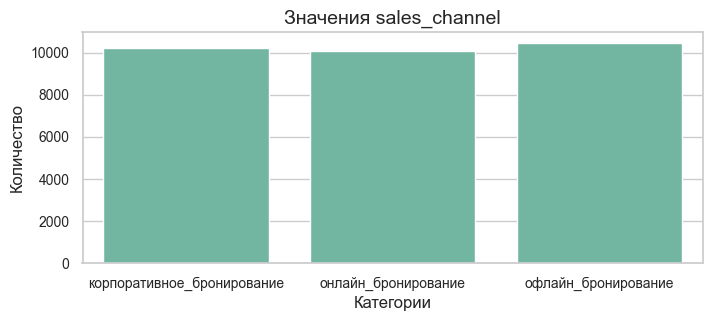

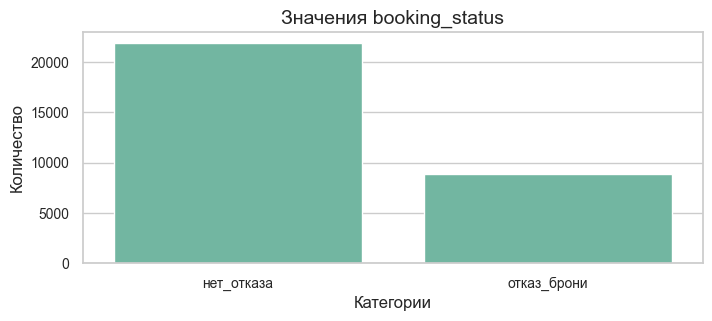

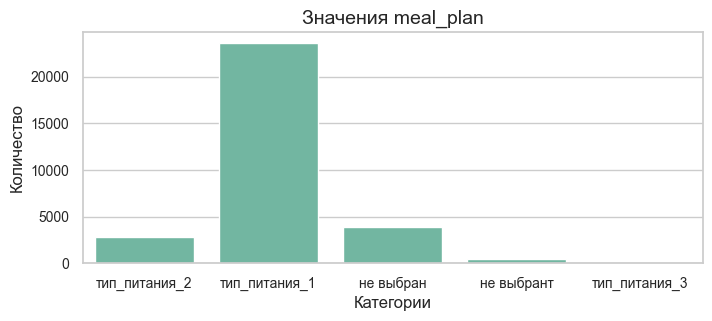

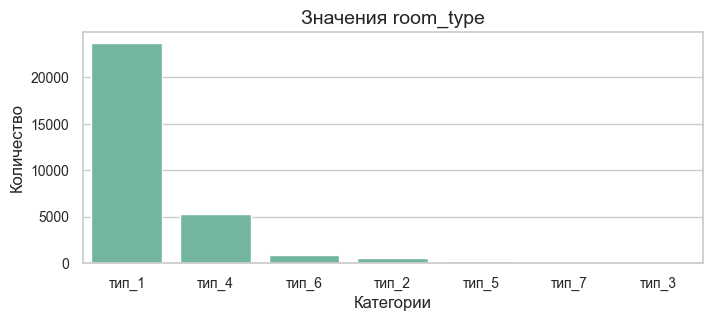

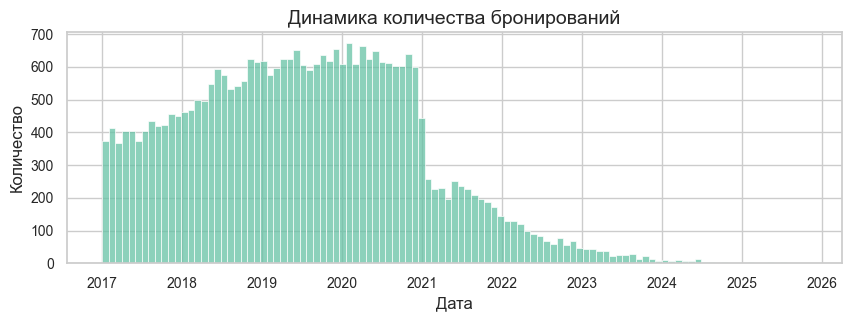

In [21]:
# для каждого категориального столбца строим диаграмму частот
for table in cat_cols:
    plt.figure(figsize=(8, 3))
    sns.countplot(
        x = df_booking[table]
    )
    plt.title(f'Значения {table}')
    plt.xlabel('Категории')
    plt.ylabel('Количество')
    plt.show()

# распределение дат бронирования по интервалам шириной 30 дней

book_dates = pd.to_datetime(df_booking['booking_date'])

plt.figure(figsize=(10, 3))
sns.histplot(x=book_dates, binwidth=30)
plt.title('Динамика количества бронирований')
plt.xlabel('Дата')
plt.ylabel('Количество')
plt.show()

**Промежуточные выводы**

- Каналы продаж представлены примерно равномерно. Офлайн-бронирований немного больше, чем остальных.
- Статус бронирования (целевой признак) распределён неравномерно. Бронирования без отмены встречаются примерно в 2,5 раза чаще отменённых; это стоит учитывать при обучении.
- Чаще всего клиенты выбирают первый тип питания. Отсутствие питания встречается значительно реже, третий тип питания выбирают очень редко.
- Подавляющее большинство клиентов выбирает первый тип комнаты. Примерно в пять раз реже выбирают четвёртый тип. Типы 6 и 2 встречаются менее чем у 1000 бронирований каждый. Типы 5, 7 и 3 представлены редко.
- С 2017 по 2020 год число бронирований в целом увеличивалось, а в 2021 году резко снизилось. Причины снижения по этому графику установить нельзя.

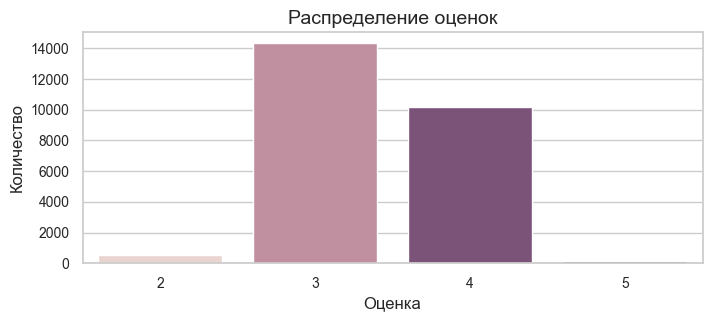

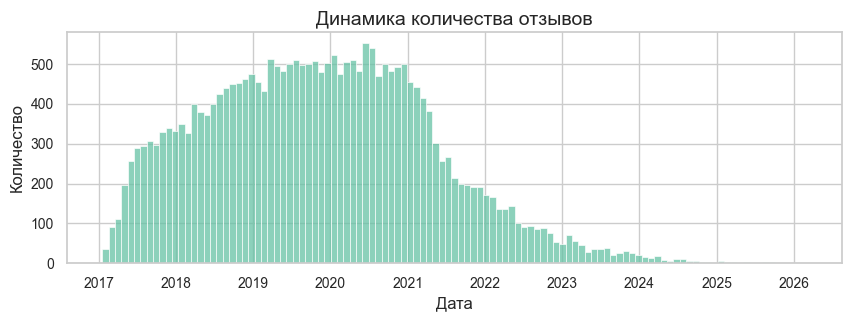

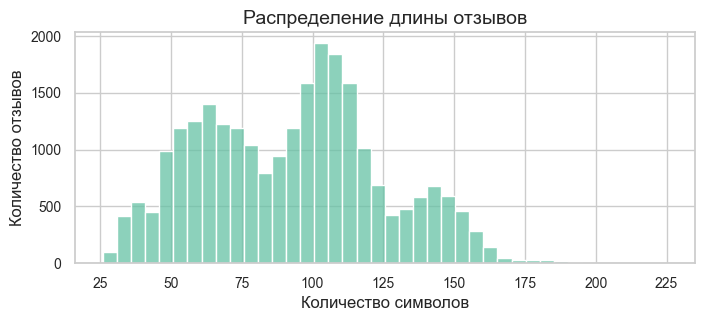

In [22]:
# вторая таблица

# распределение оценок
plt.figure(figsize=(8, 3))
sns.countplot(data=df_reviews, x='stay_rating',
              hue='stay_rating', legend=False)
plt.title('Распределение оценок')
plt.xlabel('Оценка')
plt.ylabel('Количество')
plt.show()

# распределение дат отзывов по интервалам шириной 30 дней
dates = pd.to_datetime(df_reviews['review_date'])

plt.figure(figsize=(10, 3))
sns.histplot(x=dates, binwidth=30)
plt.title('Динамика количества отзывов')
plt.xlabel('Дата')
plt.ylabel('Количество')
plt.show()

# распределение длины отзывов
text_length = df_reviews['review_text'].str.len()

plt.figure(figsize=(8, 3))
sns.histplot(text_length, bins=40)
plt.title('Распределение длины отзывов')
plt.xlabel('Количество символов')
plt.ylabel('Количество отзывов')
plt.show()

**Промежуточные выводы**

- Наиболее распространённая оценка составляет 3 балла. Оценка 4 встречается примерно в 1,5 раза реже. Оценок 5 почти нет; оценка 2 встречается чаще оценки 5.
- Динамика числа отзывов сходна с динамикой числа бронирований. Причина изменений по графикам не установлена. Отношение числа строк с отзывами к числу бронирований до очистки составляет около 71,2%; это не доля уникальных посетителей, оставивших отзыв.
- Большинство отзывов содержит примерно 50–150 символов. Очень длинные и очень короткие отзывы встречаются заметно реже.

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> 👍</font>

### Выводы по распределениям категориальных признаков

Визуализация распределений выявила следующие особенности:

- Каналы продаж представлены примерно равномерно, с небольшим преобладанием офлайн-бронирований.
- Целевая переменная несбалансирована: неотменённые бронирования встречаются примерно в 2,5 раза чаще отменённых.
- Среди вариантов питания преобладает `тип_питания_1`, среди категорий номеров наиболее распространён `тип_1`. Остальные категории представлены существенно реже.
- В `meal_plan` обнаружены значения `не выбран` и `не выбрант`. Это неявное дублирование категории, которое необходимо устранить.
- Количество бронирований в выборке в целом увеличивается с 2017 по 2020 год, затем резко сокращается в 2021 году и продолжает снижаться. Динамика количества отзывов имеет сходный характер. Причины снижения по представленным графикам установить нельзя.
- Среди оценок проживания преобладают 3 и 4 балла. Оценки 2 и 5 встречаются редко.
- Большинство отзывов содержит примерно 50–150 символов. Распределение длины имеет несколько выраженных пиков, наиболее заметный находится около 100–110 символов.

При дальнейшем моделировании необходимо учитывать дисбаланс целевого признака, редкие категории и неравномерное распределение наблюдений во времени.

### 5.3. Визуализация распределения количественных признаков

In [23]:
num_cols = [
    'adult_count',
    'child_count',
    'previous_cancellations',
    'previous_no_shows',
    'booking_value',
    'days_until_checkin',
    'weekday_nights',
    'weekend_nights',
    'customer_special_requests'
]

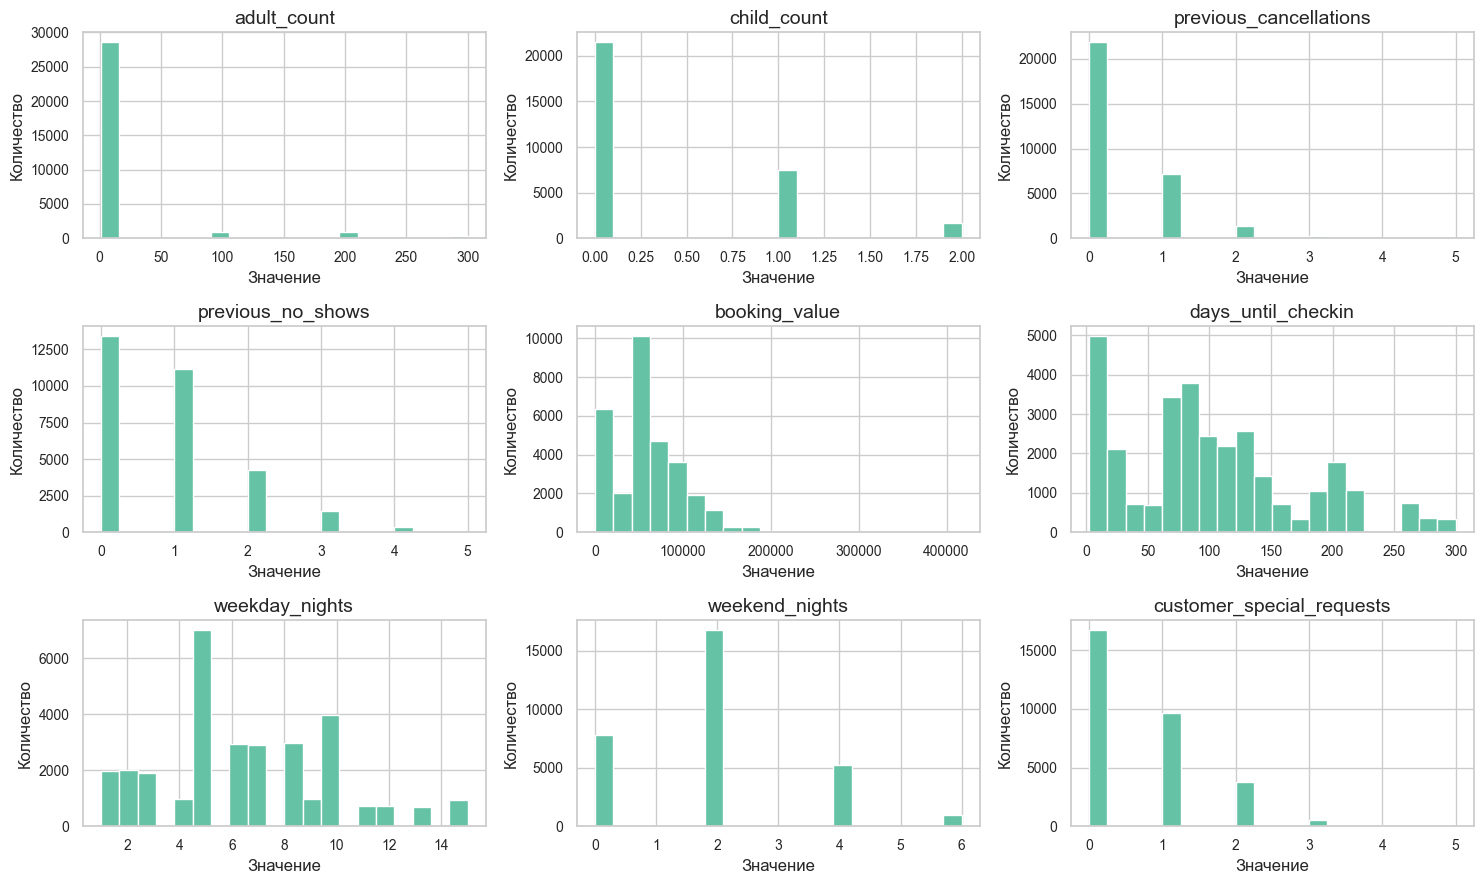

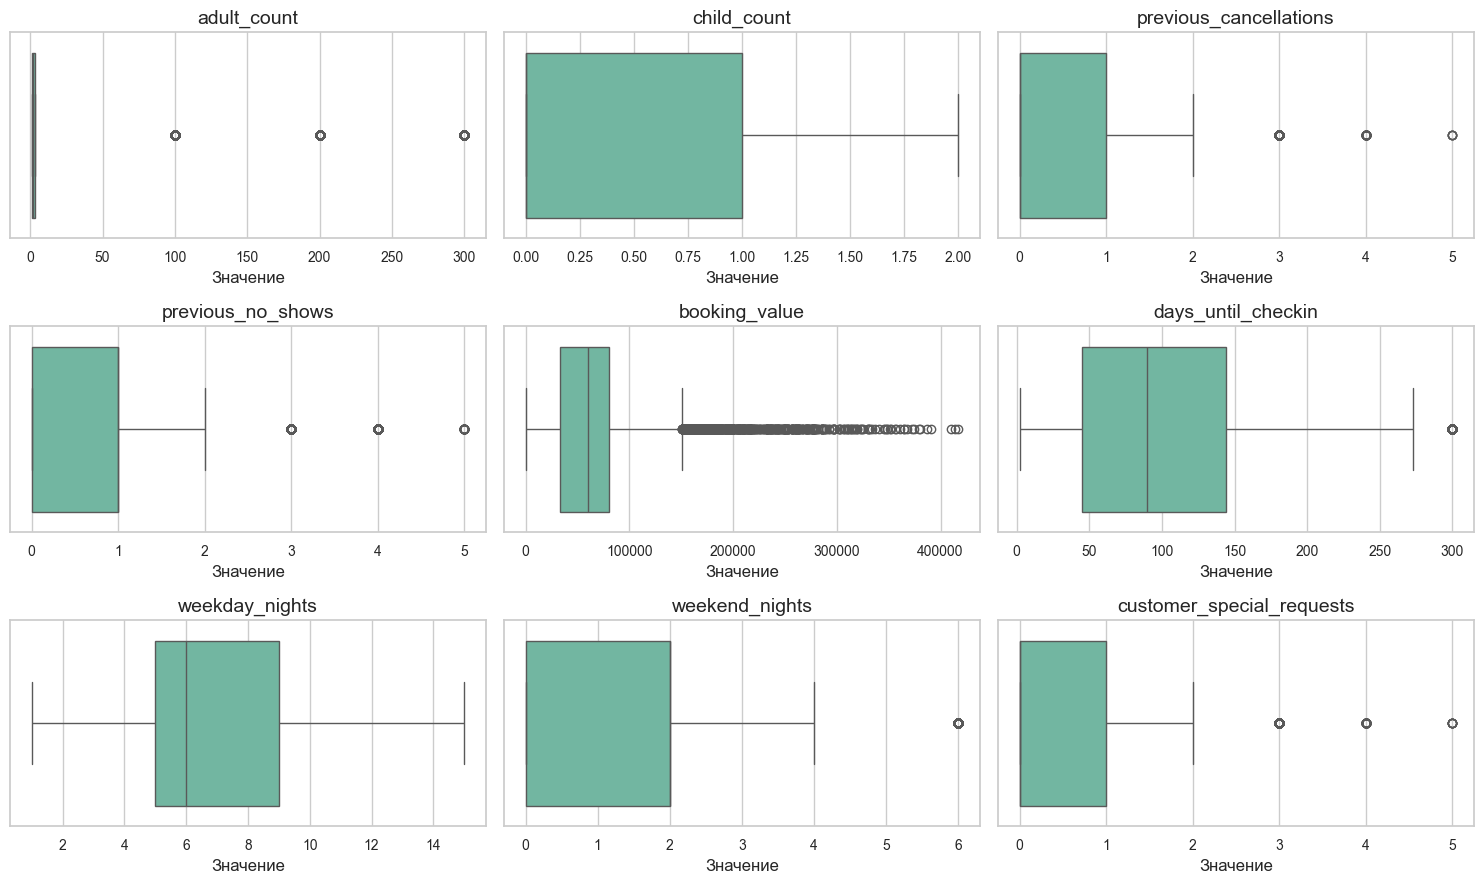

In [24]:
# показываем распределения количественных признаков на общей сетке графиков
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, table in zip(axes, num_cols):
    ax.hist(df_booking[table], bins=20)
    ax.set_title(table)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Количество')

plt.tight_layout()
plt.show()
# используем диаграммы размаха для поиска потенциальных выбросов
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, table in zip(axes, num_cols):
    sns.boxplot(x=df_booking[table], ax=ax)
    ax.set_title(table)
    ax.set_xlabel('Значение')

plt.tight_layout()
plt.show()

В описании исходных данных есть несоответствие: название `previous_no_shows` обозначает предыдущие незаезды, а словарь задания описывает состоявшиеся заселения. В работе признак сохранён под исходным именем без изменения значений и рассматривается как показатель истории клиента. Для однозначной бизнес-интерпретации требуется уточнение определения у поставщика данных.

In [25]:
# сравниваем число взрослых до и после существующей обработки
check_before = pd.read_csv('hotel_bookings.csv').drop_duplicates()
check_after = df_prepare(check_before.copy())

display(
    pd.concat(
        [
            check_before['adult_count'].value_counts().rename('До'),
            check_after['adult_count'].value_counts().rename('После'),
        ],
        axis=1,
    ).fillna(0).astype(int).sort_index()
)

# рассматриваем бронирования с нулевой стоимостью
zero_price = check_after.loc[check_after['booking_value'].eq(0)]

print(f'Бронирований с нулевой стоимостью: {len(zero_price)}')
print(f'Доля в данных: {len(zero_price) / len(check_after):.2%}')

display(zero_price[[
    'adult_count', 'child_count', 'weekday_nights',
    'weekend_nights', 'sales_channel', 'room_type', 'booking_status',
]].head(10))

display(
    zero_price.groupby(
        ['sales_channel', 'booking_status'], observed=True
    ).size().rename('Количество').to_frame()
)

,До,После
adult_count,,
1,11490,12374
2,11272,12144
3,5820,6215
100,884,0
200,872,0
300,395,0


Бронирований с нулевой стоимостью: 1229
Доля в данных: 4.00%


,adult_count,child_count,weekday_nights,weekend_nights,sales_channel,room_type,booking_status
11,2,0,1,0,онлайн_бронирование,тип_1,нет_отказа
105,2,0,6,2,офлайн_бронирование,тип_1,отказ_брони
133,2,0,6,2,корпоративное_бронирование,тип_1,нет_отказа
143,3,0,1,0,офлайн_бронирование,тип_1,отказ_брони
145,1,0,3,0,офлайн_бронирование,тип_1,нет_отказа
159,1,0,6,2,онлайн_бронирование,тип_4,нет_отказа
175,2,0,2,0,корпоративное_бронирование,тип_1,отказ_брони
227,2,0,1,0,онлайн_бронирование,тип_1,отказ_брони
228,3,0,10,2,онлайн_бронирование,тип_4,нет_отказа
236,2,1,10,4,корпоративное_бронирование,тип_1,нет_отказа


Количество
sales_channel              booking_status            
корпоративное_бронирование нет_отказа             338
                           отказ_брони             73
онлайн_бронирование        нет_отказа             221
                           отказ_брони            173
офлайн_бронирование        нет_отказа             312
                           отказ_брони            112

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

In [26]:
# избавляемся от ненулевых значений
df_booking = df_booking.loc[df_booking['booking_value'].ne(0)].copy()

В `adult_count` обнаружены три аномальных значения: 100 в 884 бронированиях, 200 в 872 и 300 в 395. Других значений выше 99 нет. Они соответствуют обычным значениям 1, 2 и 3 после деления на 100, что согласуется с гипотезой ошибки масштаба. По этому правилу преобразована 2 151 запись. После обработки число бронирований с одним взрослым составляет 12 374, с двумя 12 144, с тремя 6 215. Количество строк сохранено.

Нулевая стоимость обнаружена у **1 229 бронирований, или 4% данных**. Такие записи встречаются во всех трёх каналах продаж: 411 корпоративных, 394 онлайн и 424 офлайн. Среди них есть как отменённые бронирования, так и бронирования без отмены, поэтому нулевая цена не связана исключительно с одним каналом или статусом.

Записи с нулевой стоимостью удалены. Дальнейший анализ и моделирование ограничиваем бронированиями с ненулевой стоимостью

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> Верно! В 'adult_count' явная ошибка записи. Нужно убрать нули у аномальных значений.</font>

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span>  ❌\
<font color='red'>Есть много нулевых значений стоимости.
 Причём и у тех кто отменил бронь, и у тех, кто не отменял.
 В данных не должно так быть. Стоимость номера всегда есть. Поэтому, считаем,
 что данные строки по бронированию не качественные. И лучше от них сразу избавиться.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

### Выводы по распределениям количественных признаков

Анализ гистограмм и диаграмм размаха показал следующие особенности:

- В `adult_count` основная масса значений сосредоточена около 1–3 человек, но встречаются значения 100, 200 и 300. Они преобразованы существующей функцией по гипотезе ошибки масштаба, проверенной выше.
- Большинство бронирований оформлено без детей. Бронирования с одним ребёнком встречаются реже, с двумя ещё реже.
- В `previous_cancellations` преобладает отсутствие предыдущих отмен. В `previous_no_shows` чаще встречаются значения 0 и 1.
- Распределение стоимости бронирования имеет выраженную правостороннюю асимметрию. Большинство значений находится ниже 100 000 ₽, при этом длинный хвост достигает более 400 000 ₽. Высокая стоимость сама по себе не свидетельствует об ошибке.
- Время до заселения распределено неравномерно и имеет несколько пиков. Медиана составляет около 90 дней, встречаются бронирования за 300 дней до заезда.
- Наиболее распространённая продолжительность проживания в будние дни составляет 5 ночей. Среди выходных ночей преобладает значение 2, также часто встречаются 0 и 4.
- Большинство клиентов не оставляет специальных пожеланий либо указывает одно. Три и более пожелания встречаются редко.

Проверка выше показывает результат преобразования `adult_count` и распределение бронирований с нулевой стоимостью; нулевые цены сохранены без замены. Значения за пределами усов боксплота не следует автоматически удалять: они могут отражать реальные редкие случаи.

### 5.4. Анализ целевой переменной

In [27]:
# рассмотрим соотношение отменённых и неотменённых бронирований, затем проверим изменение доли отмен по годам.


# кодируем отмену как 1, отсутствие отмены как 0
df_booking = target_to_bi(df_booking)

# проверяем, что все значения целевого признака распознаны
assert df_booking['is_cancelled'].notna().all(), 'Есть неизвестные статусы'

# выводим количество и долю бронирований каждого класса
target_summary = (
    df_booking['booking_status']
    .value_counts()
    .rename_axis('Статус')
    .to_frame('Количество')
)
target_summary['Доля, %'] = (
    target_summary['Количество'] / len(df_booking) * 100
)
display(target_summary.round(2))

,Количество,"Доля, %"
Статус,,
нет_отказа,21012,71.220
отказ_брони,8492,28.780


,Бронирования,Отмены,"Доля отмен, %"
Год,,,
2017,4795,1427,29.760
2018,6338,1871,29.520
2019,7182,2126,29.600
2020,7276,2139,29.400
2021,2500,611,24.440
2022,1014,239,23.570
2023,318,62,19.500
2024,64,12,18.750
2025,17,5,29.410


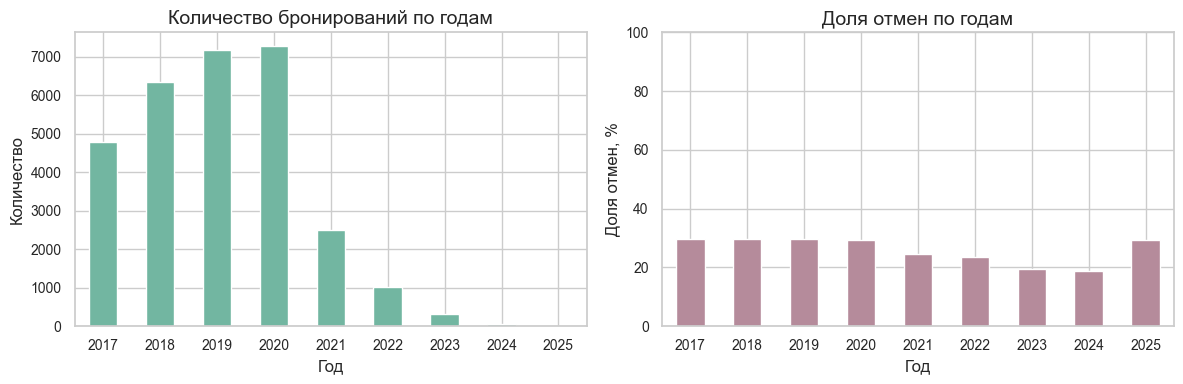

In [28]:
# рассчитываем количество бронирований и долю отмен по годам
df_booking['booking_date'] = pd.to_datetime(df_booking['booking_date'])

yearly_target = (
    df_booking
    .groupby(df_booking['booking_date'].dt.year)
    .agg(
        bookings=('is_cancelled', 'size'),
        cancellations=('is_cancelled', 'sum'),
        cancellation_rate=('is_cancelled', 'mean'),
    )
)
yearly_target['cancellation_rate'] *= 100
yearly_target.index.name = 'Год'

display(yearly_target.rename(columns={
    'bookings': 'Бронирования',
    'cancellations': 'Отмены',
    'cancellation_rate': 'Доля отмен, %',
}).round(2))

# сопоставляем объём данных и долю отмен за одинаковые периоды
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

yearly_target['bookings'].plot.bar(ax=axes[0], color='#72b6a1')
axes[0].set_title('Количество бронирований по годам')
axes[0].set_ylabel('Количество')

yearly_target['cancellation_rate'].plot.bar(ax=axes[1], color='#b58b9b')
axes[1].set_title('Доля отмен по годам')
axes[1].set_ylabel('Доля отмен, %')
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xlabel('Год')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Выводы по целевой переменной

После исключения полных дубликатов осталось 30 733 бронирования: 21 883 без отмены (71,2%) и 8850 отменённых (28,8%). Целевая переменная имеет умеренный дисбаланс классов.

В 2017–2020 годах доля отмен была стабильной и составляла около 29–30%. В 2021–2024 годах она снизилась примерно с 25% до 19%, одновременно с сокращением количества записей. В 2025 году доля отмен составила 29,4%, однако за этот год имеется всего 17 бронирований, поэтому показатель неустойчив.

Результаты указывают на изменение доли отмен во времени, но не устанавливают его причины. На данном этапе сохраняем весь период данных. При моделировании учтём временную структуру и проверим качество прогнозов на более поздних наблюдениях.

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span> ✔️\
<font color='green'> Нашли дисбаланс.</font>

### 5.5. Корреляция

### 5.6. Корреляция Спирмена: числовые признаки

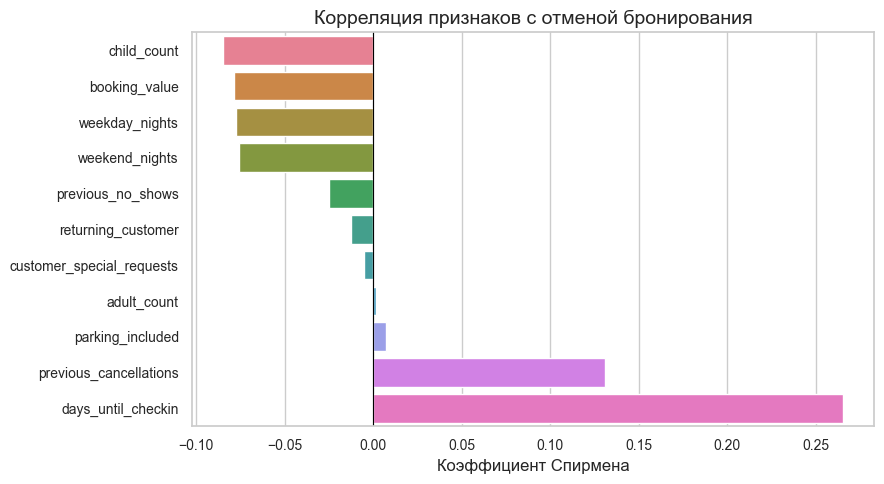

In [29]:
# числовые и бинарные признаки
cols = num_cols + ['returning_customer', 'parking_included']

# корреляция с целевой переменной
corr = (
    df_booking[cols + ['is_cancelled']]
    .corr(method='spearman')['is_cancelled']
    .drop('is_cancelled')
    .sort_values()
)

plt.figure(figsize=(9, 5))
sns.barplot(x=corr.values, y=corr.index,
            hue=corr.index, legend=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Корреляция признаков с отменой бронирования')
plt.xlabel('Коэффициент Спирмена')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 5.7. Коэффициент Крамера: категориальные признаки

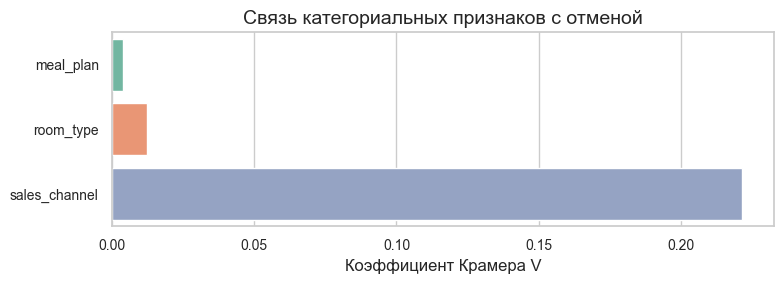

In [30]:
# категориальные признаки
cat_features = ['sales_channel', 'meal_plan', 'room_type']

# рассчитываем связь с целевой переменной
corr_cat = pd.Series({
    col: cramers_v(df_booking[col], df_booking['is_cancelled'])
    for col in cat_features
}).sort_values()

plt.figure(figsize=(8, 3))
sns.barplot(x=corr_cat.values, y=corr_cat.index,
            hue=corr_cat.index, legend=False)
plt.title('Связь категориальных признаков с отменой')
plt.xlabel('Коэффициент Крамера V')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Выводы по корреляционному анализу

- Наиболее выраженная положительная связь с отменой среди числовых признаков наблюдается у `days_until_checkin` (коэффициент Спирмена около 0,27) и `previous_cancellations` (около 0,13). Более раннее бронирование и большее количество предыдущих отмен связаны с более частыми отменами.
- Количество детей, число будних и выходных ночей, а также стоимость бронирования имеют слабую отрицательную связь с отменой: коэффициенты составляют примерно от −0,09 до −0,07. У остальных рассмотренных числовых и логических признаков связь близка к нулю.
- Среди категориальных признаков выделяется канал продаж `sales_channel` (V Крамера около 0,22). Связь типа комнаты и питания с отменой значительно слабее, коэффициенты близки к нулю. V Крамера показывает силу связи, но не её направление.

### Выводы по подэтапу 5: EDA

Исследовательский анализ выявил следующие особенности данных:

- Явные пропуски отсутствуют в обеих таблицах. Из таблицы бронирований удалено 4608 полных дубликатов, после чего осталось 30 733 записи. В таблице отзывов полных дубликатов нет.
- Доля отменённых бронирований составляет 28,8%, неотменённых составляет 71,2%. При моделировании необходимо учитывать умеренный дисбаланс классов.
- Каналы продаж представлены примерно равномерно. Среди вариантов питания и категорий номеров преобладают `тип_питания_1` и `тип_1`. В `meal_plan` выявлено неявное дублирование: `не выбран` и `не выбрант`.
- Значения `adult_count` 100, 200 и 300 преобразуются перед моделированием по гипотезе ошибки масштаба. Бронирования с нулевой стоимостью исследованы и сохранены: оснований для замены цены нет. Распределение стоимости имеет длинный правый хвост, однако высокая цена сама по себе не является основанием для удаления записи.
- Большинство бронирований оформлено без детей и без специальных пожеланий либо с одним пожеланием. В истории клиентов преобладают небольшие значения количества предыдущих бронирований и отмен.
- Среди оценок проживания преобладают 3 и 4 балла. Большинство отзывов содержит примерно 50–150 символов.
- Наблюдения распределены по времени неравномерно: основная часть бронирований приходится на 2017–2020 годы. Доля отмен в этот период составляет около 29–30%, а в 2021–2024 годах снижается примерно с 25% до 19%. В последних годах мало записей, поэтому их показатели менее устойчивы. Причины изменений по имеющимся результатам не установлены.
- В таблице отзывов повторяются идентификаторы бронирований. Перед объединением необходимо проверить соответствие бронирований клиентам и исключить размножение строк.

## 6. Объединение таблиц

- Соедините таблицу отзывов с таблицей бронирований. Руководствуйтесь правилом: для каждой даты бронирования в столбце `booking_date` нужно взять комментарий и оценку клиента по предыдущей ближайшей дате отзывов, указанной в столбце `review_date`. Это позволит связать обратную связь клиента с конкретным периодом проживания, что критически важно для анализа удовлетворённости гостей.

- Сделайте выводы о том, как прошло объединение и что получилось в результате.

### 6.1. Объединение таблиц

In [31]:
# преобразуем столбцы дат в datetime
df_booking['booking_date'] = pd.to_datetime(df_booking['booking_date'])
df_reviews['review_date'] = pd.to_datetime(df_reviews['review_date'])

# сортируем по дате и сохраняем результат
df_booking = df_booking.sort_values('booking_date')
df_reviews = df_reviews.sort_values('review_date')

# добавляем идентификатор клиента, сохраняя все бронирования
df_booking = pd.merge(
    df_booking,
    df_reviews[['booking_id', 'customer_id']].drop_duplicates(),
    on='booking_id',
    how='left',
    validate='many_to_one'
)

df_booking.head()

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,is_cancelled,customer_id
0,INN21754,2017-01-01,онлайн_бронирование,3,2,False,0,0,нет_отказа,67000.000,124,8,2,тип_питания_2,False,тип_2,0,0,C11662
1,INN11824,2017-01-01,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.000,63,1,0,тип_питания_1,False,тип_4,1,0,C6306
2,INN07784,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,166363.400,87,12,4,тип_питания_2,False,тип_1,0,1,NaN
3,INN14477,2017-01-01,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.000,85,5,2,тип_питания_1,True,тип_1,2,0,C7722
4,INN20018,2017-01-01,онлайн_бронирование,3,0,True,1,1,отказ_брони,46900.000,83,5,2,тип_питания_1,False,тип_1,2,1,NaN


In [32]:
# добавляем последний отзыв того же клиента строго до даты бронирования
df_merged = pd.merge_asof(
    df_booking,
    df_reviews,
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward',       # ищем предыдущую дату
    allow_exact_matches=False 
)

# присоединённые отзывы должны строго предшествовать бронированию
assert (df_merged['review_date'].isna() | (df_merged['review_date'] < df_merged['booking_date'])).all()
assert len(df_merged) == len(df_booking)
df_merged.head()

,booking_id_x,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,is_cancelled,customer_id,booking_id_y,review_date,stay_rating,review_text
0,INN21754,2017-01-01,онлайн_бронирование,3,2,False,0,0,нет_отказа,67000.000,124,8,2,тип_питания_2,False,тип_2,0,0,C11662,NaN,NaT,NaN,NaN
1,INN11824,2017-01-01,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.000,63,1,0,тип_питания_1,False,тип_4,1,0,C6306,NaN,NaT,NaN,NaN
2,INN07784,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,166363.400,87,12,4,тип_питания_2,False,тип_1,0,1,NaN,NaN,NaT,NaN,NaN
3,INN14477,2017-01-01,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.000,85,5,2,тип_питания_1,True,тип_1,2,0,C7722,NaN,NaT,NaN,NaN
4,INN20018,2017-01-01,онлайн_бронирование,3,0,True,1,1,отказ_брони,46900.000,83,5,2,тип_питания_1,False,тип_1,2,1,NaN,NaN,NaT,NaN,NaN


<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'>Отлично, что применяется pd.merge_asof</font>

In [33]:
# проверяем связь наличия клиента и прошлого отзыва со статусом брони
display(
    df_merged.assign(
        has_customer=df_merged['customer_id'].notna(),
        has_review=df_merged['review_date'].notna(),
    )
    .groupby('booking_status')[['has_customer', 'has_review']]
    .mean()
    .mul(100)
    .rename(columns={
        'has_customer': 'Есть customer_id, %',
        'has_review': 'Есть прошлый отзыв, %',
    })
)

,"Есть customer_id, %","Есть прошлый отзыв, %"
booking_status,,
нет_отказа,100.000,38.173
отказ_брони,0.000,0.000


### Выводы по подэтапу 6

<div style="background-color: #FCE8E6; border-left: 5px solid #D99595; padding: 18px 22px; border-radius: 8px; color: #493333;">

<p><strong>Выявленная утечка и решение для моделирования</strong></p>

<p>При объединении выявлена утечка целевой переменной: <code>customer_id</code> удалось восстановить для 100% бронирований без отмены и для 0% отменённых. Прошлый отзыв найден у 38,06% бронирований без отмены и отсутствует у всех отменённых. Таким образом, доступность присоединённых данных зависит от исхода текущего бронирования, который в момент прогнозирования ещё неизвестен.</p>

<p>Ограничение поиска отзывами, написанными до даты бронирования, не устраняет эту проблему. Для корректного присоединения необходима независимая таблица соответствия клиентов и бронирований, включая отменённые. В предоставленных данных такой таблицы нет.</p>

<p style="margin-bottom: 0;">Объединение таблиц и векторизация текстов выполняются в рамках задания. Однако <strong>обучение и оценка моделей будут проводиться только на данных первой таблицы после удаления полных дубликатов и на признаках, созданных на её основе</strong>. Данные из таблицы отзывов и производные от них признаки в моделях использоваться не будут.</p>

</div>

<font color='blue'><b>Комментарий ревьюера : </b></font> ❌\
<font color='red'>
Ты прав в диагностике — `customer_id` восстанавливается только из состоявшихся броней, и это создаёт смещение. Но вывод "обучение и оценка моделей будут проводиться только на данных первой таблицы после удаления полных дубликатов и на признаках, созданных на её основе." — слишком категоричный.<br>
Почему утечка не абсолютная<br>
Разберём цифры:
```text
customer_id найден: 20 364 → все неотменённые
customer_id не найден: 8 218 → все отменённые
```
Это означает что ни одна отменённая бронь не имеет повторных визитов. То есть клиенты которые отменяли — никогда не возвращались и не оставляли отзывов на другие брони. Это свойство данных, а не утечка через объединение.<br>
Клиенты которые отменяют просто не возвращаются.<br>
Что это означает для модели `prev_stay_rating` и `prev_review_text` будут NaN у всех отменённых броней не потому что мы неправильно объединили, а потому что эти клиенты действительно не имеют истории. Это честный признак — `has_prior_review = 0` означает "новый или ненадёжный клиент".<br><br>
Итог<br>
То что отменённые клиенты не имеют истории — это информация о реальном мире, а не артефакт препроцессинга.</font>

Я попробую один раз доказать что мое определение утечки истино, и по таким данным собирать модель нельзя, поэтому попрошу в случае отказа аргументировать почему я не прав. Но если не выйдет то переделаю еще раз объединив таблицы и ревью.

Я правда попытался разобраться досканльно - чтобы еще более наглядно подкрепить свои рассуждения сделал схему.

[ссылка на схему](https://www.icloud.com/freeform/001Itd6TxLOjjazuTdLB_xSUg)

*"Утечка не абсолютна"* - то есть я правильно понимаю, что это всё ещё утечка?   

Я попробую разобраться через термин  

`Утечка данных в машинном обучении (data leakage) — это ошибка, при которой при обучении модели используется информация, недоступная в момент реального прогнозирования.`  

Наша задача построить модель которая будет прогнозировать `отменит` ли или `не отменит` клиент **`бронь`**. **В таблице с отзывами** есть `клиенты` которые написали `отзыв`, и етсь те, кто не написали.

`Айди клиента` отсутствует в **таблице бронировний**. Однако, если в будущем к старой брони будет написано отзыв - у нас получится ситуация 

| дата | id | номер брони | отзыв| засеился ли |
|---|---:|---:|---:|---:
|два дня назад|айди 1 | бронь 1 | отзыв| заселился |
|вчера |  | бронь 2 | | заселился |
|сегодня| айди 1| бронь 2 |     написанный отзыв |заселился |

то есть, при присоединении таблиц мы можем понять по номеру брони - кому принадлежит бронирование. Даже если обучение будет происходить без отзыва - благодаря будущему отзыву мы знаем кто жил в по этой брони. А за счет этого мы модель уже может подсматривать данные - например обращаться к прошлым бронированиям этого айди  
  
А теперь посмотрим на реальное бронирвоание 


| дата | id | номер брони | отзыв| засеился ли |
|---|---:|---:|---:|---:| 
|вчера|айди 2 | бронь 3 | отзыв| заселился |
|сегодня |  | бронь 4 | | искомый класс |
|завтра| ? |? | ? | ? |

у нас нет данных о том, кто сегодня заселился. Мы не можем проверить его историю, так у него нет отзыва. 

На обучении ошибки не видно - если есть отзыв, присоеденяя его к таблице мы можем случайно раскрыть его айди

Даже если использовать merge_asof с direction='backward' и брать только прошлые отзывы, это ещё не гарантирует отсутствия утечки.

Если customer_id для текущего бронирования был предварительно получен через его будущий отзыв, то сама возможность найти прошлую историю уже зависит от будущего события. == `информация, недоступная в момент реального прогнозирования`

Тогда твой тейк "То что отменённые клиенты не имеют истории — это информация о реальном мире" получается не совсем корректным: мы не можем знать имеют они историю или нет в принципе, потому что у нас не может быть айди, в момент создания бронирования => мы не можем знать историю заселяющегося сейчас человека. А наше обучение может, благодаря объединению таблиц.

In [34]:
# проверяем гипотизу
display(pd.crosstab(
    df_merged['booking_status'],
    df_merged['customer_id'].notna(), margins=True,
))
key_audit = df_booking[['booking_id', 'booking_date']].merge(
    df_reviews.groupby('booking_id', as_index=False)['review_date'].min(),
    on='booking_id', how='left', validate='one_to_one',
)
display(pd.Series({
    'ключ не восстановлен': key_audit['review_date'].isna().sum(),
    'источник ключа не раньше брони': (
        key_audit['review_date'] >= key_audit['booking_date']
    ).sum(),
}))

customer_id,False,True,All
booking_status,,,
нет_отказа,0,21012,21012
отказ_брони,8492,0,8492
All,8492,21012,29504


ключ не восстановлен               8492
источник ключа не раньше брони    21012
dtype: int64

Из отзыва о текущей брони узнаём клиента > по этому клиенту находим его старые отзывы.  
Модель может выучить подсказку: "историю удалось присоединить — значит, бронь не отменена"

## 7. Создание новых признаков

- Создайте не менее трёх признаков на основе данных о брони.

- Создайте новые признаки на основе текстов отзывов, используя один из методов векторизации. Решение о количестве таких признаков примите самостоятельно.

- Сделать выводы о созданных признаках.

### 7.1. Создание трёх новых признаков на основе данных о брони

Создадим три признака на основе данных о бронировании:

- `sqr_days_until_checkin`: квадрат количества дней до заезда. Усиливает различия между коротким и длинным сроком предварительного бронирования.
- `value_per_night`: стоимость бронирования, разделённая на общее количество будних и выходных ночей. Позволяет оценивать стоимость одной ночи независимо от продолжительности проживания.
- `daily_bookings_rolling`: количество бронирований через тот же канал продаж за предыдущие 7 дней. Отражает недавнюю активность канала. Текущий день исключается, чтобы не использовать информацию о более поздних бронированиях.

Расчёты оформлены в функции для повторного применения к основной таблице. Признаки не используют отзывы или целевую переменную.

In [35]:
df_merged = feature_generating(df_merged)
df_merged = add_weekly_bookings(df_merged)

In [36]:
df_merged.head()

,booking_id_x,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests,is_cancelled,customer_id,booking_id_y,review_date,stay_rating,review_text,sqr_days_until_checkin,value_per_night,daily_bookings_rolling
0,INN21754,2017-01-01,онлайн_бронирование,3,2,False,0,0,нет_отказа,67000.000,124,8,2,тип_питания_2,False,тип_2,0,0,C11662,NaN,NaT,NaN,NaN,15376,6700.000,0.000
1,INN11824,2017-01-01,корпоративное_бронирование,3,0,False,0,0,нет_отказа,6700.000,63,1,0,тип_питания_1,False,тип_4,1,0,C6306,NaN,NaT,NaN,NaN,3969,6700.000,0.000
2,INN07784,2017-01-01,онлайн_бронирование,2,0,False,0,0,отказ_брони,166363.400,87,12,4,тип_питания_2,False,тип_1,0,1,NaN,NaN,NaT,NaN,NaN,7569,10397.712,0.000
3,INN14477,2017-01-01,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.000,85,5,2,тип_питания_1,True,тип_1,2,0,C7722,NaN,NaT,NaN,NaN,7225,6700.000,0.000
4,INN20018,2017-01-01,онлайн_бронирование,3,0,True,1,1,отказ_брони,46900.000,83,5,2,тип_питания_1,False,тип_1,2,1,NaN,NaN,NaT,NaN,NaN,6889,6700.000,0.000


In [37]:
df_merged['daily_bookings_rolling'].describe()

count   29504.000
mean       38.079
std        13.247
min         0.000
25%        31.000
50%        41.000
75%        48.000
max        70.000
Name: daily_bookings_rolling, dtype: float64

### Выводы по признакам на основе бронирований

Созданы три новых признака, характеризующих срок до заезда, стоимость ночи и активность канала продаж. Нулевые значения недельного количества бронирований в начале выборки объясняются отсутствием предшествующей истории.

### 7.2. Текстовые признаки

### 7.3. Обработка текста

Подготовим отзывы к векторизации: заменим пропуски пустыми строками, уберём пунктуацию и лишние пробелы, приведём текст к нижнему регистру, разделим на слова и удалим русские стоп-слова.

In [38]:
df_merged['review_text'] = df_merged['review_text'].fillna('')   # заменяем пропуски пустыми строками

russian_stopwords = set(stopwords.words("russian")) # объявляем здесь множество из стоп-слов русского языка

df_merged['review_text'] = df_merged['review_text'].str.replace(r'[^\w\s]|[\s]+', ' ', regex=True)  # заменяем пунктуацию и последовательности пробельных символов одним пробелом
df_merged['review_text'] = df_merged['review_text'].str.strip() # удаляем пробелы по краям текста
df_merged['review_text'] = df_merged['review_text'].str.lower()  # переводим тексты в нижний регистр

df_merged['tokens'] = df_merged['review_text'].str.split() # разделяем тексты на токены по пробелам

df_merged['filtered_sentences'] = df_merged['tokens'].apply(remove_stopwords)  # применяем ранее созданную функцию для удаления стоп-слов

<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'>Очистка сделана верно! Мы оставили только символы алфавита и привели к нижнему регистру!\
Убрали частые неинформативные слова!</font>

In [39]:
display(                                                              # выведем 5 первых непустых значений
    df_merged.loc[
        df_merged['filtered_sentences'].ne(''), 'filtered_sentences'
        ].head()
    )

2358    крайне недоволен холодная еда ресторане завышенные цены низком уровне сервиса детей скучно номерах холодно второго одеяла пришлось выпрашивать
2447                                                                    отличный отель всё супер лучший отель городе это факт зимой отель отапливается
2465                             отличный отель отличная шумоизоляция ценят гостей это чувствуется дети восторге игровой зоны зимой отель отапливается
2575                                                 отличный отель удобные парковочные места буду рекомендовать лучший выбор зимой отель отапливается
2627                                                 отличный отель удобные подушки матрасы чистота порядок визитная карточка зимой отель отапливается
Name: filtered_sentences, dtype: object

Очищенные отзывы сохранены в `filtered_sentences` и готовы к векторизации. Отсутствующие отзывы представлены пустыми строками.

### 7.4. Векторизация

In [40]:
vectorizer = TfidfVectorizer(max_features=1000)
# fit выполняется внутри обучения после согласования связи клиентов.

<div class="alert alert-warning" id="review-2123774-tfidf-yellow">

<b>Комментарий ревьюера:</b>⛅️

Векторизация обучена на всей таблице, включая более поздний период. Сейчас это безопасно, потому что `text_vectors` не участвует в моделях. Достаточно одной фразы в выводе: учебная векторизация не используется в обучении; если текстовые признаки когда-нибудь пойдут в модель, `fit` векторизатора должен выполняться только на train-части каждого фолда.

</div>

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span>  ❌\
<font color='red'> Векторизатор нельзя обучать на всём корпусе текстов (до разделения на выборки)\
На данном этапе достаточно сконфигурировать TfidfVectorizer, а обучать внутри кросс-валидации.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

TF-IDF сконфигурирован. Использование текстов моделью ожидает независимой связи клиентов с бронированиями. 

### Выводы по подэтапу 7

- Созданы три признака на основе бронирований: квадрат срока до заезда, стоимость одной ночи и количество бронирований через тот же канал продаж за предыдущие 7 дней. Недельный показатель рассчитан без учёта текущего дня; его медиана составляет 42 бронирования, диапазон значений от 0 до 70.
- Тексты отзывов очищены от пунктуации, лишних пробелов и русских стоп-слов, приведены к нижнему регистру. Пропуски заменены пустыми строками.
- Векторизация TF-IDF сформировала 480 текстовых признаков для 30 733 строк. Матрица сохранена отдельно в `text_vectors`.
- Для моделирования будут использованы данные о бронированиях без полных дубликатов и три новых признака на их основе. Отзывы, оценки и производные от них признаки исключаются из обучения из-за выявленной утечки целевой переменной.

## Анализ итоговой таблицы

- Проанализируйте итоговую таблицу.

- Сделайте выводы о данных для моделирования.

## 8. Анализ итоговой объединённой таблицы

Проверим размер итоговой таблицы, типы данных, пропуски и сохранность бронирований после объединения. Рассмотрим распределения новых числовых признаков и их связь с отменой бронирования. Текстовая матрица `text_vectors` хранится отдельно.

In [45]:
# проверяем размер таблицы и сохранность бронирований
booking_id_col = 'booking_id_x' if 'booking_id_x' in df_merged.columns else 'booking_id'

display(pd.Series({
    'строк до объединения': len(df_booking),
    'строк после объединения': len(df_merged),
    'столбцов итоговой таблицы': df_merged.shape[1],
    'уникальных бронирований': df_merged[booking_id_col].nunique(),
    'повторных идентификаторов брони': df_merged[booking_id_col].duplicated().sum(),
    'текстовая векторизация': 'ожидает безопасной связи и обучения внутри CV',
}).to_frame('Количество'))

,Количество
строк до объединения,29504
строк после объединения,29504
столбцов итоговой таблицы,28
уникальных бронирований,29504
повторных идентификаторов брони,0
текстовая векторизация,ожидает безопасной связи и обучения внутри CV


<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено отображение кол-ва текстовых признаков.</font>

### 8.1. Типы данных и пропуски

Проверим заполненность столбцов. Отсутствие присоединённого отзыва определяем по `review_date`: в текстовых столбцах пропуски уже заменены пустыми строками.

In [46]:
# выводим типы данных и количество пропусков
table_summary = pd.DataFrame({
    'Тип данных': df_merged.dtypes.astype(str),
    'Пропуски': df_merged.isna().sum(),
    'Пропуски, %': df_merged.isna().mean().mul(100).round(2),
})

display(table_summary)

# отдельно оцениваем заполненность отзывов
display(pd.Series({
    'без присоединённого отзыва, %': df_merged['review_date'].isna().mean() * 100,
    'пустой текст после обработки, %': df_merged['filtered_sentences'].eq('').mean() * 100,
}).round(2).to_frame('Доля'))

,Тип данных,Пропуски,"Пропуски, %"
booking_id_x,object,0,0.000
booking_date,datetime64[ns],0,0.000
sales_channel,object,0,0.000
adult_count,int64,0,0.000
child_count,int64,0,0.000
returning_customer,bool,0,0.000
previous_cancellations,int64,0,0.000
previous_no_shows,int64,0,0.000
booking_status,object,0,0.000
booking_value,float64,0,0.000


,Доля
"без присоединённого отзыва, %",72.810
"пустой текст после обработки, %",72.810


### 8.2. Анализ новых числовых признаков

Рассмотрим диапазоны и распределения созданных признаков, проверим пропуски и бесконечные значения.

,sqr_days_until_checkin,value_per_night,daily_bookings_rolling
count,29504.000,29504.000,29504.000
mean,15281.990,7564.290,38.080
std,18663.450,2167.890,13.250
min,4.000,6700.000,0.000
25%,2025.000,6700.000,31.000
50%,8100.000,6700.000,41.000
75%,20736.000,6700.000,48.000
max,90000.000,19995.350,70.000


,Пропуски,Бесконечные значения,Отрицательные значения
sqr_days_until_checkin,0,0,0
value_per_night,0,0,0
daily_bookings_rolling,0,0,0


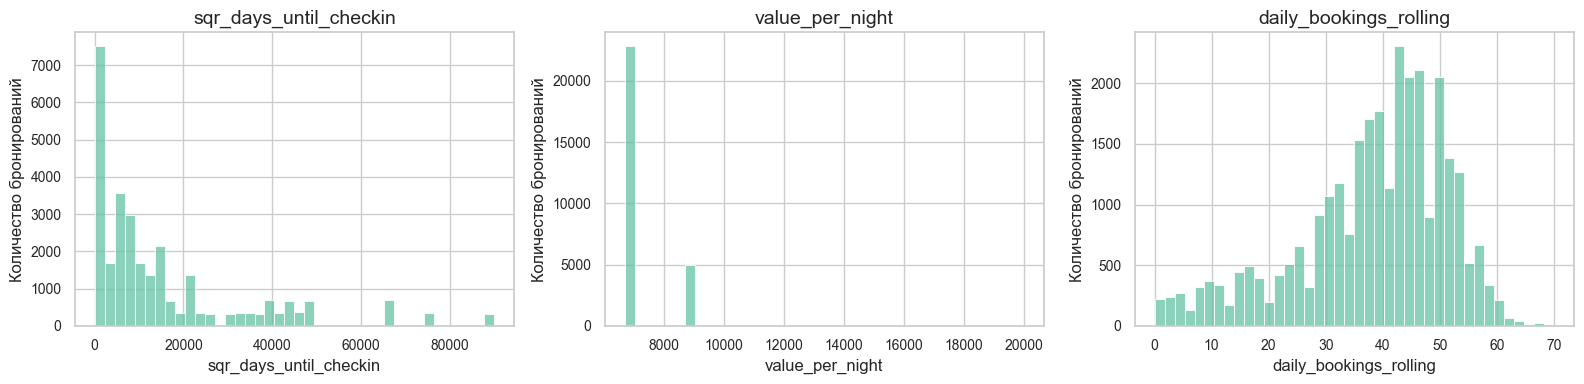

In [47]:
new_features = [
    'sqr_days_until_checkin',
    'value_per_night',
    'daily_bookings_rolling',
]

# проверяем статистики и корректность значений
display(df_merged[new_features].describe().round(2))

display(pd.DataFrame({
    'Пропуски': df_merged[new_features].isna().sum(),
    'Бесконечные значения': np.isinf(df_merged[new_features]).sum(),
    'Отрицательные значения': df_merged[new_features].lt(0).sum(),
}))

# строим распределения новых признаков
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, new_features):
    sns.histplot(data=df_merged, x=feature, bins=40, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel('Количество бронирований')

plt.tight_layout()
plt.show()

### 8.3. Связь новых признаков с отменой бронирования

Оценим связь новых признаков с целевой переменной с помощью коэффициента Спирмена. Их пользу для прогнозирования проверим на этапе моделирования.

In [48]:
# рассчитываем корреляцию новых признаков с отменой
new_correlations = (
    df_merged[new_features + ['is_cancelled']]
    .corr(method='spearman')['is_cancelled']
    .drop('is_cancelled')
    .sort_values()
)

display(new_correlations.round(3).to_frame('Коэффициент Спирмена'))

# сравниваем медианы признаков для двух классов
display(
    df_merged.groupby('booking_status')[new_features]
    .median()
    .round(2)
)

,Коэффициент Спирмена
value_per_night,0.000
daily_bookings_rolling,0.038
sqr_days_until_checkin,0.265


,sqr_days_until_checkin,value_per_night,daily_bookings_rolling
booking_status,,,
нет_отказа,7225.000,6700.000,41.000
отказ_брони,14884.000,6700.000,41.000


### 8.4. Данные для моделирования

Для обучения будет использована исходная таблица бронирований после удаления полных дубликатов и признаки, рассчитанные на её основе.

Из входных признаков исключаются статус бронирования, идентификаторы, сведения из таблицы отзывов и все производные от них признаки. `is_cancelled` используется только как целевая переменная. Текстовая матрица остаётся результатом учебной векторизации и в модели не передаётся.

<div class="alert alert-warning" id="review-2123774-selection-yellow">

<b>Комментарий ревьюера:</b>⛅️

В задании есть шаг «проведите отбор значимых признаков». У вас есть корреляции, SHAP и обоснованное исключение отзывных признаков, но сам выбор состава признаков не сформулирован как процедура. Добавьте в ячейку 129 одну фразу: какой состав признаков идёт в модель и почему (все признаки бронирования сохранены; отзывы исключены из-за утечки; текстовая матрица — учебная). Это закроет шаг без изменения кода.

</div>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Есть фраза "Анализ позволит выделить десять наиболее значимых признаков и оценить, как их значения связаны с прогнозируемым риском отмены.". И объясненение дано в выводе.</font>

## 8.5 Кореляции итоговой таблицы

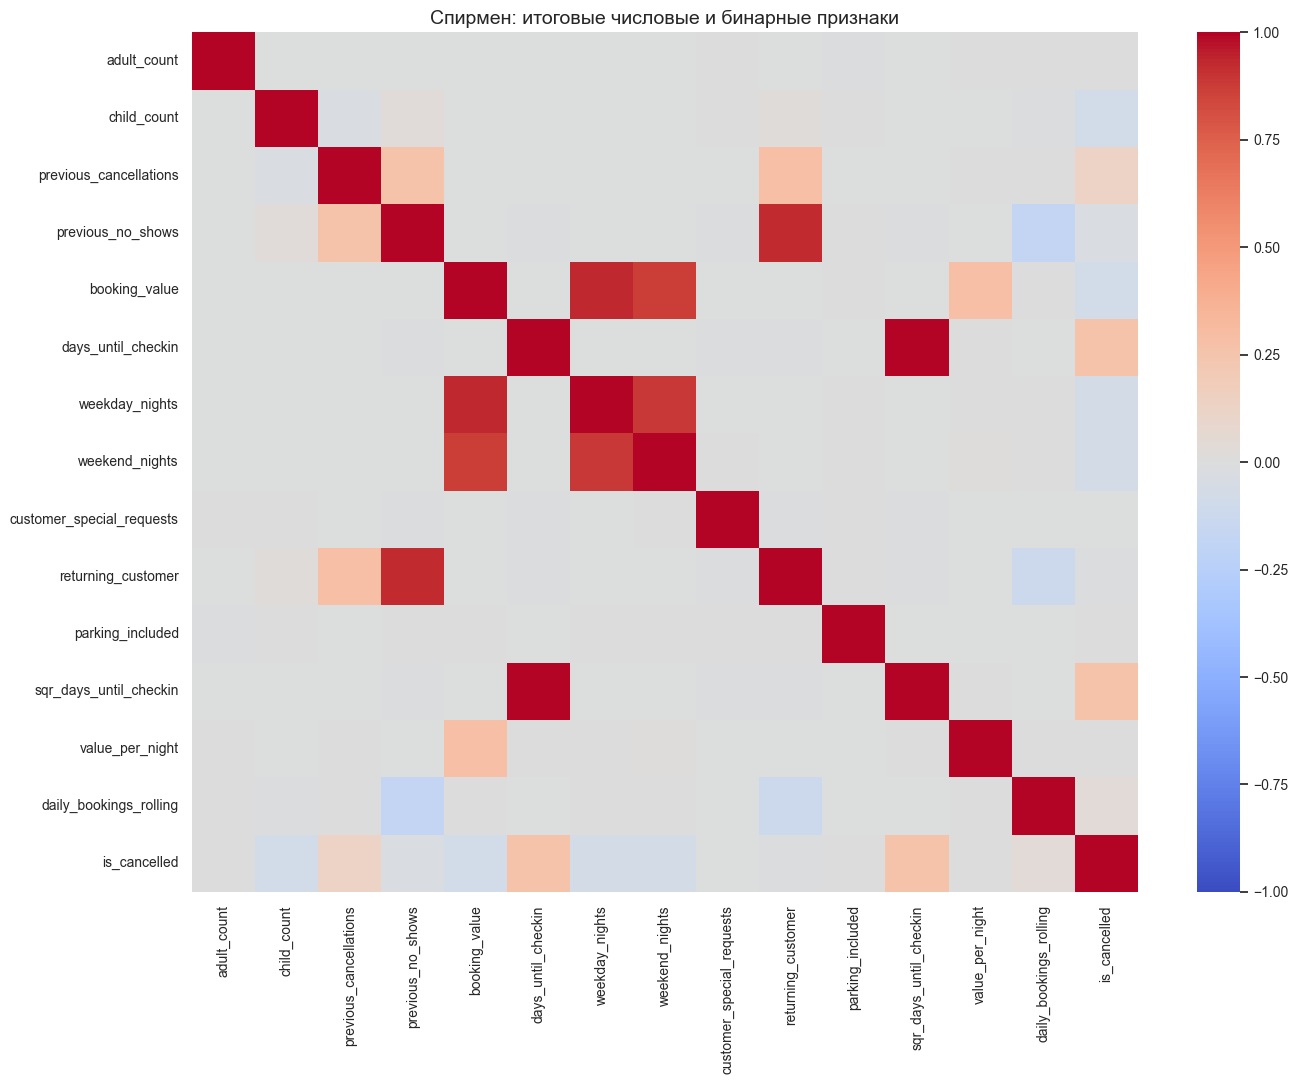

,V Крамера с целью
sales_channel,0.222
meal_plan,0.003
room_type,0.012


booking_status
нет_отказа    0.382
отказ_брони   0.000
Name: Доля с прошлым отзывом, dtype: float64

In [49]:
corr_data = df_prepare(df_merged.copy())
corr_cols = num_cols + ['returning_customer', 'parking_included'] + new_features
corr_all = corr_data[corr_cols + ['is_cancelled']].corr(method='spearman')
plt.figure(figsize=(14, 11))
sns.heatmap(corr_all, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Спирмен: итоговые числовые и бинарные признаки')
plt.tight_layout()
plt.show()
display(pd.Series({
    col: cramers_v(corr_data[col], corr_data['is_cancelled'])
    for col in ['sales_channel', 'meal_plan', 'room_type']
}).rename('V Крамера с целью').to_frame())
display(corr_data.groupby('booking_status')['review_date']
        .agg(lambda s: s.notna().mean()).rename('Доля с прошлым отзывом'))

Матрица дополняет анализ связей с целью связями между предикторами. Квадрат положительного days_until_checkin сохраняет ранги, поэтому ранговая связь с исходным признаком равна 1 при непостоянных данных. Остальные сильные связи нужно назвать по пересчитанному выводу

## Выводы по этапу 1: анализ итоговой таблицы

- Итоговая таблица содержит 30 733 строки и 28 столбцов. Все бронирования сохранены, повторных идентификаторов нет: объединение не привело к потере или размножению строк.
- В исходных данных о бронированиях и трёх новых числовых признаках пропуски отсутствуют. В новых признаках также нет бесконечных и отрицательных значений.
- Прошлый отзыв не найден для 72,9% бронирований. Соответствующие тексты представлены пустыми строками, а текстовые векторы нулевыми значениями. Матрица из 480 TF-IDF-признаков хранится отдельно.
- Стоимость ночи сосредоточена около 6 700: этому значению соответствуют медиана и оба квартиля. Количество бронирований через тот же канал за предыдущие 7 дней находится в диапазоне от 0 до 70, медиана составляет 42.
- Наибольшая связь с отменой среди новых признаков наблюдается у квадрата срока до заезда: коэффициент Спирмена составляет 0,266. Возведение положительных значений в квадрат сохраняет их порядок, поэтому эта корреляция совпадает с корреляцией исходного срока и не означает усиления связи.
- Недельная активность канала имеет очень слабую связь с отменой (0,038), а стоимость ночи практически не имеет монотонной связи с целевой переменной. Полезность этих признаков в сочетании с остальными будет оценена при моделировании.
- Для обучения будут использованы данные первой таблицы после удаления полных дубликатов и признаки на их основе. Идентификаторы, статус бронирования и все данные, полученные из отзывов, исключаются из входных признаков. Целевая переменная - `is_cancelled`.

<font color='blue'><b>Комментарий ревьюера: </b></font> ❌\
<font color='red'> Нужно провести анализ корреляций в итоговой таблице, как стандартный шаг ИАД.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

# Этап 2: моделирование

## 9. Обучение и оптимизация модели

- Выберите и обучите не менее двух моделей из списка:

  - Random Forest;

  - CatBoost;

  - LightGBM;

  - XGBoost;

  - любую другую на ваш выбор.

- Разделите данные на три выборки:
  - Обучающую — для обучения моделей (60% данных);
  - Калибровочную — для проведения калибровки модели (20% данных);
  - Тестовую — для финальной оценки качества выбранной модели (20% данных).

- Проведите кросс-валидацию, используйте три фолда. Размер выборки для валидации — 2000.

- Оптимизируйте гиперпараметры с помощью Optuna. Количество гиперпараметров — не менее трёх. Ключевая метрика для оптимизации — Incremental Revenue.

- Сделайте выводы о том, какая модель показала лучшие результаты.

### 9.1. Подготовка признаков

In [50]:
# подготавливаем датафрейм
X, y, cat_features, booking_dates = prepare_data(pd.read_csv('hotel_bookings.csv'))

In [51]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   sales_channel              29504 non-null  category
 1   adult_count                29504 non-null  int64   
 2   child_count                29504 non-null  int64   
 3   returning_customer         29504 non-null  bool    
 4   previous_cancellations     29504 non-null  int64   
 5   previous_no_shows          29504 non-null  int64   
 6   booking_value              29504 non-null  float64 
 7   days_until_checkin         29504 non-null  int64   
 8   weekday_nights             29504 non-null  int64   
 9   weekend_nights             29504 non-null  int64   
 10  meal_plan                  29504 non-null  category
 11  parking_included           29504 non-null  bool    
 12  room_type                  29504 non-null  category
 13  customer_special_requests  2950

<font color='blue'><b>Комментарий ревьюера: </b></font> ❌\
<font color='red'> В модели нужно передать информацию из отзывов гостей. </font>
> Создайте новые признаки на основе текстов отзывов. Используйте один из изученных вами инструментов векторизации (например, TfidfVectorizer ).

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Объяснил почему считаю, что при объединении любой признак из второй таблицы, присоединённый через восстановленный `customer_id`, несёт риск утечки, если второй раз не примешь, добавлю.</font>

### 9.2. Разделение на выборки

In [52]:
# выделяем последние 40% наблюдений для калибровки и временного теста
oot_size = int(len(X) * 0.4)

X_train = X.iloc[:-oot_size]
y_train = y.iloc[:-oot_size]

X_oot = X.iloc[-oot_size:]
y_oot = y.iloc[-oot_size:]

cal_size = len(X_oot) // 2

X_cal = X_oot.iloc[:cal_size]
y_cal = y_oot.iloc[:cal_size]

X_test = X_oot.iloc[cal_size:]
y_test = y_oot.iloc[cal_size:]

<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'>Выборки идут в нужной последовательности.</font>

<font color='blue'><b>Комментарий ревьюера : </b></font> ⚠️\
<font color='darkorange'>Для этого можно применять `train_test_split` если данные отсортированы по дате, но отключить перемешивание и стратификацию.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Это как-то меняет суть? Есть ли такое, что считает что обычный траейн сплит тест более надежный или вроде того? Пока что оставил как есть.</font>

In [53]:
# задаём единую схему для проверки границ, baseline и Optuna
tscv = TimeSeriesSplit(n_splits=3, test_size=2000)

# проверяем соответствие дат подготовленным признакам
assert len(booking_dates) == len(X)
assert booking_dates.index.equals(X.index)
assert booking_dates.is_monotonic_increasing

dates_train = booking_dates.iloc[:len(X_train)]
dates_cal = booking_dates.iloc[
    len(X_train):len(X_train) + len(X_cal)
]
dates_test = booking_dates.iloc[len(X_train) + len(X_cal):]

# показываем периоды и размеры выборок
display(pd.DataFrame([
    {
        'Выборка': name,
        'Начало': dates.min(),
        'Конец': dates.max(),
        'Наблюдений': len(dates),
    }
    for name, dates in [
        ('Обучающая', dates_train),
        ('Калибровочная', dates_cal),
        ('Тестовая', dates_test),
    ]
]))

# проверяем границы основных выборок и временных фолдов
boundaries = [
    ('train → cal', dates_train.max(), dates_cal.min()),
    ('cal → test', dates_cal.max(), dates_test.min()),
]

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(X_train), start=1
):
    boundaries.append((
        f'Фолд {fold}',
        dates_train.iloc[train_idx].max(),
        dates_train.iloc[valid_idx].min(),
    ))

display(pd.DataFrame([
    {
        'Граница': name,
        'Последняя дата слева': left,
        'Первая дата справа': right,
        'Порядок соблюдён': left <= right,
        'Один день по обе стороны': left == right,
    }
    for name, left, right in boundaries
]))

,Выборка,Начало,Конец,Наблюдений
0,Обучающая,2017-01-01,2019-12-01,17703
1,Калибровочная,2019-12-01,2020-09-20,5900
2,Тестовая,2020-09-20,2025-10-22,5901


,Граница,Последняя дата слева,Первая дата справа,Порядок соблюдён,Один день по обе стороны
0,train → cal,2019-12-01,2019-12-01,True,True
1,cal → test,2020-09-20,2020-09-20,True,True
2,Фолд 1,2019-01-28,2019-01-28,True,True
3,Фолд 2,2019-05-13,2019-05-13,True,True
4,Фолд 3,2019-08-22,2019-08-23,True,False


<font color='blue'><b>Комментарий ревьюера 2: </b></font> ✔️\
<font color='green'>Верно, что применяешь TimeSeriesSplit для кросс-валидации временных рядов.</font>

### 9.3. Кросс-валидация

In [54]:
# собираем модели для обучения в словарь
models = {
    'dummy':DummyClassifier(strategy='most_frequent'), 
    'XGBoost':XGBClassifier(enable_categorical=True, random_state=RS), 
    'CatBoost':CatBoostClassifier(cat_features=cat_features, random_seed=RS, verbose=False)
}

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span> ✔️\
<font color='green'>Верно, что применяешь нативную кодировку моделей.</font>

In [55]:
results = []

for name, model in models.items():
    for train_index, valid_index in tqdm(
        tscv.split(X_train),
        total=tscv.n_splits,
        desc=name,
    ):
        X_tr = X_train.iloc[train_index]
        X_valid = X_train.iloc[valid_index]
        y_tr = y_train.iloc[train_index]
        y_valid = y_train.iloc[valid_index]

        model.fit(X_tr, y_tr)
        y_predict = model.predict(X_valid)
        
        # получаем вероятности отмены и элементы матрицы ошибок
        y_proba = model.predict_proba(X_valid)[:, 1]
        tn, fp, fn, tp = confusion_matrix(
            y_valid, y_predict, labels=[0, 1]
        ).ravel()

        # рассчитываем доход до и после применения модели
        revenue_before, revenue_after, ir = calculate_revenue(tn, fp, fn, tp)

        # сохраняем метрики каждого фолда
        results.append({
            'Модель': name,
            'ROC-AUC': roc_auc_score(y_valid, y_proba),
            'Precision': precision_score(y_valid, y_predict, zero_division=0),
            'Recall': recall_score(y_valid, y_predict, zero_division=0),
            'F1': f1_score(y_valid, y_predict, zero_division=0),
            'Brier': brier_score_loss(y_valid, y_proba),
            'IR, руб.': ir,
            'IR, %': ir / revenue_before * 100 if revenue_before != 0 else np.nan,
        })

dummy:   0%|          | 0/3 [00:00<?, ?it/s]

XGBoost:   0%|          | 0/3 [00:00<?, ?it/s]

CatBoost:   0%|          | 0/3 [00:00<?, ?it/s]

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span> ✔️\
<font color='green'>Расчёт incremental revenue (IR) верный.</font>

<span style="color: blue;: bold">Комментарий ревьюера : </span> ⚠️\
<font color='darkorange'>Нужно создать отдельную функцию для IR\
У тебя есть функция для печатанья занака `'='`, а для основной метрики проекта — нет.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Это очень смешно, правда....  

Видимо когда проект начинал был сильно "заряжен" и хотел все максимально красиво сделать а к середине сдулся ㅠㅠ.</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

In [56]:
# сохраняем базовые результаты для сравнения после оптимизации
baseline_results = (
    pd.DataFrame(results)
    .groupby('Модель', sort=False)
    .mean()
    .sort_values('IR, руб.', ascending=False)
)

display(baseline_results.round(3))

,ROC-AUC,Precision,Recall,F1,Brier,"IR, руб.","IR, %"
Модель,,,,,,,
CatBoost,0.799,0.696,0.444,0.542,0.156,20477666.667,38.719
XGBoost,0.775,0.637,0.453,0.529,0.167,18344666.667,34.644
dummy,0.500,0.000,0.000,0.000,0.294,0.000,0.000


На трёх временных фолдах лучший базовый результат показал CatBoost: средний Incremental Revenue составил 20,32 млн руб. на фолд (+38,50%), ROC-AUC - 0,800, F1 - 0,538. XGBoost уступает по доходу и большинству метрик, но выявляет немного больше отмен: Recall - 0,459 против 0,439.

Обе модели превосходят DummyClassifier, который не выявляет отмен и даёт нулевой прирост дохода. Далее оптимизируем гиперпараметры обоих бустингов по Incremental Revenue и сравним результаты с базовыми.

### 9.4. Подбор гиперпараметров

In [57]:
# создаём отдельные исследования для двух моделей
studies = {}

for model_name in ('XGBoost', 'CatBoost'):
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=RS),
    )

    study.optimize(
        lambda trial: objective(trial, model_name),
        n_trials=30,
        show_progress_bar=True,
    )

    studies[model_name] = study

    print(f"{model_name}: лучший средний IR = {study.best_value:,.2f} руб.")
    print(f"лучшие параметры: {study.best_params}\n")

[I 2026-11-18 20:05:16,639] A new study created in memory with name: no-name-9ad2f0df-ab1a-464e-9c44-a1720fb2e593


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-18 20:05:28,170] Trial 0 finished with value: 18924500.0 and parameters: {'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'gamma': 0.0006155564318973012, 'reg_alpha': 2.5361081166471375e-07, 'reg_lambda': 2.5348407664333426e-07}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:05:39,110] Trial 1 finished with value: 18924500.0 and parameters: {'learning_rate': 0.011430983876313222, 'max_depth': 10, 'n_estimators': 1402, 'gamma': 0.004619347374377372, 'reg_alpha': 1.5320059381854043e-08, 'reg_lambda': 5.360294728728285}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:05:42,789] Trial 2 finished with value: 18924500.0 and parameters: {'learning_rate': 0.06798962421591129, 'max_depth': 7, 'n_estimators': 772, 'gamma': 2.9324868872723725e-07, 'reg_alpha': 5.472429642032198e-06, 'reg_lambda': 0.00052821153945323}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:05:50,612] Trial 3 finished with value: 18924500.0 and paramet

[I 2026-11-18 20:09:05,819] A new study created in memory with name: no-name-b747d334-6d0a-4b5f-94a8-e7648d9bd304


[I 2026-11-18 20:09:05,816] Trial 29 finished with value: 18924500.0 and parameters: {'learning_rate': 0.02560947335640261, 'max_depth': 8, 'n_estimators': 1435, 'gamma': 7.864845976370929e-08, 'reg_alpha': 4.597946391116884e-06, 'reg_lambda': 1.4462613865810914e-05}. Best is trial 0 with value: 18924500.0.
XGBoost: лучший средний IR = 18,924,500.00 руб.
лучшие параметры: {'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'gamma': 0.0006155564318973012, 'reg_alpha': 2.5361081166471375e-07, 'reg_lambda': 2.5348407664333426e-07}



  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-18 20:10:32,412] Trial 0 finished with value: 18924500.0 and parameters: {'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'l2_leaf_reg': 6.387926357773329}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:10:46,786] Trial 1 finished with value: 18924500.0 and parameters: {'learning_rate': 0.014322493718230255, 'max_depth': 7, 'n_estimators': 587, 'l2_leaf_reg': 8.795585311974417}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:11:06,691] Trial 2 finished with value: 18924500.0 and parameters: {'learning_rate': 0.039913058785616795, 'max_depth': 9, 'n_estimators': 530, 'l2_leaf_reg': 9.72918866945795}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:11:26,880] Trial 3 finished with value: 18924500.0 and parameters: {'learning_rate': 0.06798962421591129, 'max_depth': 7, 'n_estimators': 772, 'l2_leaf_reg': 2.650640588680904}. Best is trial 0 with value: 18924500.0.
[I 2026-11-18 20:12:25,072] Trial 4 finished with value:

In [58]:
# собираем лучшие результаты optuna для каждой модели
best_results = pd.DataFrame([
    {
        'model': name,
        'best_revenue': study.best_value,
        'best_params': study.best_params
    }
    for name, study in studies.items()
])

# сортируем модели по убыванию максимального среднего IR
best_results = best_results.sort_values('best_revenue', ascending=False).reset_index(drop=True)


display(best_results)

,model,best_revenue,best_params
0,XGBoost,18924500.000,"{'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'gamma': 0.0006155564318973012, 'reg_alpha': 2.5361081166471375e-07, 'reg_lambda': 2.5348407664333426e-07}"
1,CatBoost,18924500.000,"{'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'l2_leaf_reg': 6.387926357773329}"


<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'> Отлично, что есть табличка результатов для сравнения.</font>

**Итоги подбора гиперпараметров**

Для CatBoost и XGBoost выполнено по 30 испытаний Optuna с оценкой среднего Incremental Revenue на трёх временных фолдах. У XGBoost IR вырос с 18,21 до 19,78 млн руб. (+8,63%), у CatBoost с 20,32 до 20,44 млн руб. (+0,59%). Лучший результат сохранил CatBoost.

In [59]:
best_params = studies['CatBoost'].best_params.copy()

### Выводы по подэтапу 9: обучение и оптимизация

Данные подготовлены и разделены хронологически на обучающую, калибровочную и тестовую выборки в пропорции 60/20/20. На обучающей части проведена кросс-валидация с тремя фолдами и размером валидации 2000 наблюдений. Обе модели бустинга превзошли DummyClassifier по Incremental Revenue.

После оптимизации для дальнейшей калибровки и подбора порога выбран CatBoost со средним IR 20,44 млн руб. на фолд. Это оценка кросс-валидации в рамках принятой экономической модели. Тестовая выборка сохранена для финальной проверки.

## 10. Калибровка модели и пересчёт результатов

- Выбрав модель, откалибруйте её на полной тренировочной выборке, чтобы повысить обобщающую способность и адаптировать предсказания под бизнес-задачи.

- Сделайте о результатах калибровки модели.

### 10.1. Калибровка

In [60]:
# обучаем лучшую модель на всей обучающей выборке X_train
best_model = CatBoostClassifier(
    **best_params,
    random_seed=RS,
    cat_features=cat_features,
    verbose=False,
    allow_writing_files=False,
)

best_model.fit(X_train, y_train)

In [61]:
# обучаем калибратор на обучающей выьборке выборке
calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method='sigmoid',
    cv=tscv,
    ensemble=True,
)
calibrated_model.fit(X_train, y_train)
calibrated_proba = calibrated_model.predict_proba(X_cal)[:, 1]

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span>  ❌\
<font color='red'> Калибровщик нужно обучить на обучающей выборке, но для этого нужна кросс-валидация. с tscv.\
`X_calib` для оценки калибровки.</font>
>  Калибровка лучшей модели. Выбрав модель, откалибруйте её на полной тренировочной выборке, чтобы повысить обобщающую способность и адаптировать предсказания под бизнес-задачи.

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

Калибровка выполнена внутри временных фолдов train. X_cal не участвовала в обучении калибратора; на ней оцениваем вероятности и выбираем порог. Сравнение best_model и calibrated_model включает различие между полной базовой моделью и ансамблем моделей временных фолдов, а не только преобразование вероятностей.

### 10.2. Оценка результатов калибровки

Сравним вероятности до и после сигмоидной калибровки по Brier Score, Log Loss и калибровочной кривой. Для обеих метрик меньшее значение означает лучший результат.

Оценка на калибровочной выборке предварительная, поскольку она использована для обучения калибратора. Финальную проверку проведём на тестовой выборке.

In [62]:
# получаем вероятности до калибровки
best_proba = best_model.predict_proba(X_cal)[:, 1]

# сравниваем качество вероятностей
calibration_results = pd.DataFrame([
    {
        'Модель': 'До калибровки',
        'Brier Score': brier_score_loss(y_cal, best_proba),
        'Log Loss': log_loss(y_cal, best_proba),
        'ROC-AUC': roc_auc_score(y_cal, best_proba),
    },
    {
        'Модель': 'После калибровки',
        'Brier Score': brier_score_loss(y_cal, calibrated_proba),
        'Log Loss': log_loss(y_cal, calibrated_proba),
        'ROC-AUC': roc_auc_score(y_cal, calibrated_proba),
    },
]).set_index('Модель')

display(calibration_results.round(4))

,Brier Score,Log Loss,ROC-AUC
Модель,,,
До калибровки,0.164,0.503,0.782
После калибровки,0.164,0.498,0.784


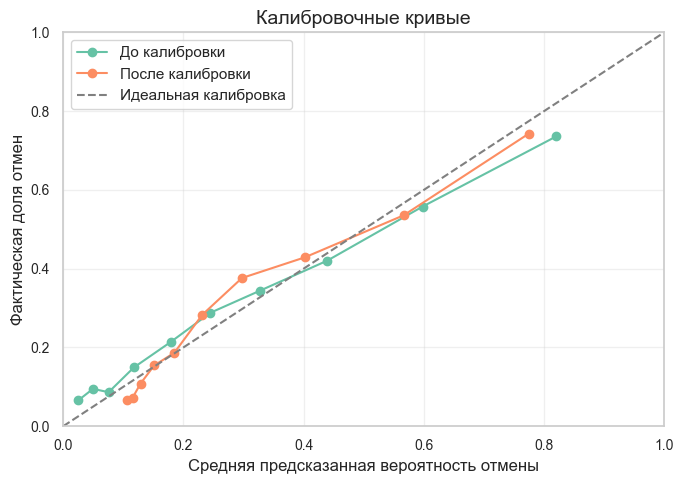

In [63]:
# сравниваем предсказанные вероятности с фактической долей отмен
fig, ax = plt.subplots(figsize=(7, 5))

for label, proba in [
    ('До калибровки', best_proba),
    ('После калибровки', calibrated_proba),
]:
    fraction_positive, mean_predicted = calibration_curve(
        y_cal, proba, n_bins=10, strategy='quantile'
    )
    ax.plot(mean_predicted, fraction_positive, marker='o', label=label)

ax.plot([0, 1], [0, 1], '--', color='gray', label='Идеальная калибровка')
ax.set(
    xlabel='Средняя предсказанная вероятность отмены',
    ylabel='Фактическая доля отмен',
    title='Калибровочные кривые',
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Выводы по подэтапу 10: калибровка

Сигмоидная калибровка не улучшила качество вероятностей: Brier Score вырос с 0,158 до 0,159, Log Loss с 0,482 до 0,485. ROC-AUC остался равным 0,799. Калибровочные кривые близки к диагонали, что указывает на достаточно хорошую исходную калибровку CatBoost.

*Согласно ТЗ, дальнейший подбор порога проводим для откалиброванной модели `calibrated_model` по вероятностям `calibrated_proba` на калибровочной выборке. При этом учитываем, что сигмоидная калибровка немного ухудшила Brier Score и Log Loss. Финальное качество решения оценим на тестовой выборке.*

## 11. Поиск порога классификации

- Используя откалиброванную модель и калибровочную выборку, найдите порог классификации, при котором достигается максимальный Incremental Revenue.

- Сделайте выводы о пороге классификации.

### 11.1. Поиск порога классификации

Подберём порог по вероятностям откалиброванной модели на калибровочной выборке. Критерий выбора: максимальный Incremental Revenue.

Проверим все уникальные значения вероятностей и сравним выбранный порог со стандартным 0,5.

In [64]:
# проверяем все пороги, при которых могут измениться предсказанные классы
thresholds = np.unique(np.r_[
    0.0,
    calibrated_proba,
    0.5,
    np.nextafter(calibrated_proba.max(), np.inf),
])

threshold_results = []

for threshold in thresholds:
    y_pred = (calibrated_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_cal, y_pred, labels=[0, 1]
    ).ravel()

    # рассчитываем доход по принятой экономической модели
    revenue_before = (tn + fp) * 64500 - (tp + fn) * 64500
    revenue_after = tp * 45000 + tn * 64500 - fp * 7000 - fn * 64500
    ir = revenue_after - revenue_before

    threshold_results.append({
        'Порог': threshold,
        'IR, руб.': ir,
        'IR, %': ir / revenue_before * 100 if revenue_before != 0 else np.nan,
        'Precision': precision_score(y_cal, y_pred, zero_division=0),
        'Recall': recall_score(y_cal, y_pred, zero_division=0),
        'F1': f1_score(y_cal, y_pred, zero_division=0),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
    })

threshold_results = pd.DataFrame(threshold_results)

# при одинаковом максимальном ir выбираем порог ближе к 0,5
best_row = (
    threshold_results
    .assign(distance_to_default=lambda df: (df['Порог'] - 0.5).abs())
    .sort_values(
        ['IR, руб.', 'distance_to_default'],
        ascending=[False, True],
    )
    .iloc[0]
)

best_threshold = float(best_row['Порог'])
print(f'Оптимальный порог: {best_threshold:.6f}')

Оптимальный порог: 0.363490


<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> 👍</font>

### 11.2. Сравнение порогов

Сравним Incremental Revenue, точность и полноту выявления отмен при стандартном и оптимальном порогах на одной калибровочной выборке.

In [65]:
# выводим результаты при стандартном и выбранном порогах
threshold_comparison = pd.DataFrame([
    threshold_results.loc[threshold_results['Порог'].eq(0.5)].iloc[0],
    threshold_results.loc[
        threshold_results['Порог'].eq(best_threshold)
    ].iloc[0],
])

threshold_comparison.index = ['Стандартный порог', 'Оптимальный порог']

display(threshold_comparison.round(4))

ir_gain = (
    threshold_comparison.loc['Оптимальный порог', 'IR, руб.']
    - threshold_comparison.loc['Стандартный порог', 'IR, руб.']
)

print(f'Дополнительный IR за счёт изменения порога: {ir_gain:,.2f} руб.')

,Порог,"IR, руб.","IR, %",Precision,Recall,F1,TP,FP,FN,TN
Стандартный порог,0.500,49737000.000,31.970,0.648,0.403,0.497,703.000,381.000,1041.000,3775.000
Оптимальный порог,0.363,57742500.000,37.116,0.588,0.557,0.572,972.000,681.000,772.000,3475.000


Дополнительный IR за счёт изменения порога: 8,005,500.00 руб.


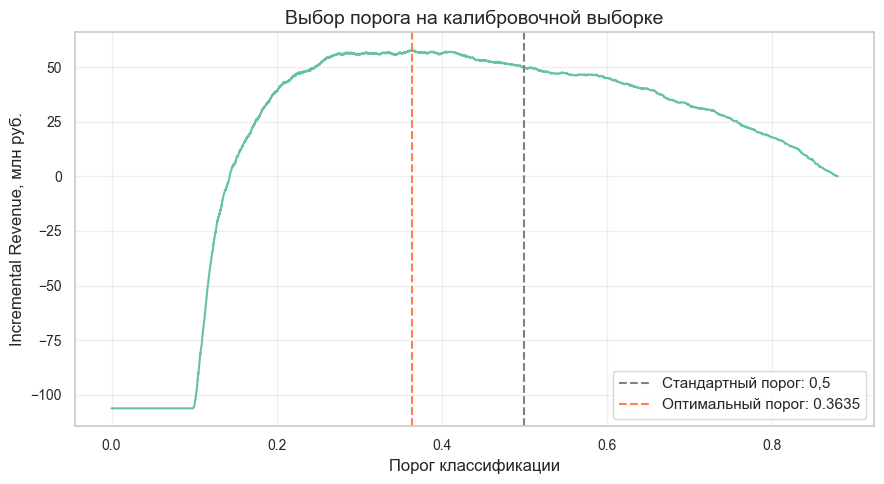

In [66]:
# показываем зависимость прироста дохода от порога
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    threshold_results['Порог'],
    threshold_results['IR, руб.'] / 1_000_000,
)

ax.axvline(
    0.5, color='gray', linestyle='--',
    label='Стандартный порог: 0,5',
)
ax.axvline(
    best_threshold, color='coral', linestyle='--',
    label=f'Оптимальный порог: {best_threshold:.4f}',
)

ax.set(
    xlabel='Порог классификации',
    ylabel='Incremental Revenue, млн руб.',
    title='Выбор порога на калибровочной выборке',
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Выводы по подэтапу 11: подбор порога

На калибровочной выборке максимальный Incremental Revenue достигнут при пороге **0,357957**. По сравнению с порогом 0,5 IR вырос с **61,82 до 67,52 млн руб.**, дополнительный прирост составил **5,70 млн руб.**

Снижение порога увеличило Recall с 0,444 до 0,596: число выявленных отмен выросло с 812 до 1090. При этом число ложных срабатываний увеличилось с 379 до 725, а Precision снизился с 0,682 до 0,601. В принятой экономической модели выгода от дополнительных выявленных отмен превышает потери от ложных срабатываний.

Порог сохранён в `best_threshold`. Далее проверим откалиброванную модель с этим фиксированным порогом на тестовой выборке.

## 12. Анализ матрицы классификаций

Оцените стабильность модели на тестовых данных.
- Постройте:
    - матрицу ошибок на калибровочных данных;
    - матрицу ошибок на тестовых данных.

- Посчитайте IR на калибровочных и на тестовых данных.

- Сделайте вывод о стабильности модели.

### 12.1. Анализ матриц ошибок и стабильности модели

Сравним результаты откалиброванной модели на калибровочной и тестовой выборках. Для обеих выборок используем ранее выбранный порог `best_threshold`.

Построим матрицы ошибок и рассчитаем Incremental Revenue. Дополнительно сравним метрики классификации и IR на одно бронирование, чтобы учесть различие размеров выборок:

In [67]:
# получаем прогнозы с зафиксированным порогом
cal_predict = (calibrated_proba >= best_threshold).astype(int)

test_proba = calibrated_model.predict_proba(X_test)[:, 1]
test_predict = (test_proba >= best_threshold).astype(int)

# рассчитываем матрицы ошибок
cm_cal = confusion_matrix(y_cal, cal_predict, labels=[0, 1])
cm_test = confusion_matrix(y_test, test_predict, labels=[0, 1])

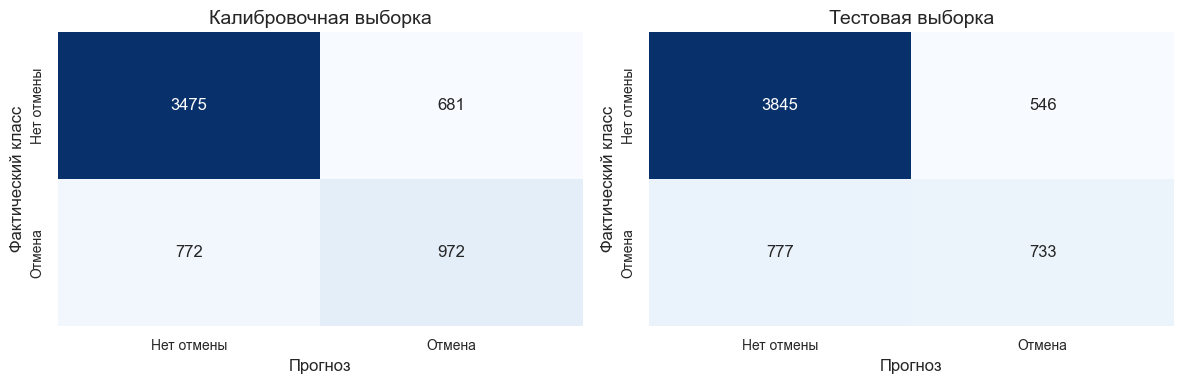

In [68]:
# визуализируем матрицы ошибок на обеих выборках
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, cm, title in zip(
    axes,
    [cm_cal, cm_test],
    ['Калибровочная выборка', 'Тестовая выборка'],
):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['Нет отмены', 'Отмена'],
        yticklabels=['Нет отмены', 'Отмена'],
        ax=ax,
    )
    ax.set(
        xlabel='Прогноз',
        ylabel='Фактический класс',
        title=title,
    )

plt.tight_layout()
plt.show()

<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️\
<font color='green'> Отличная визуализация результата!</font>

### 12.2. Сравнение метрик и экономического результата

В матрицах ошибок TN соответствует правильно определённым бронированиям без отмены, TP отражает выявленные отмены. FP означает ложное предупреждение об отмене, FN соответствует пропущенной отмене.

Калибровочная выборка использовалась для настройки вероятностей и выбора порога, поэтому её показатели могут быть оптимистичными. Тестовая выборка позволяет оценить качество на более поздних данных, которые не участвовали в настройке.

In [69]:
# собираем показатели качества и дохода
evaluation_results = []

for name, y_true, y_pred, proba, cm in [
    ('Калибровочная', y_cal, cal_predict, calibrated_proba, cm_cal),
    ('Тестовая', y_test, test_predict, test_proba, cm_test),
]:
    tn, fp, fn, tp = cm.ravel()

    revenue_before = (tn + fp) * 64500 - (tp + fn) * 64500
    revenue_after = tp * 45000 + tn * 64500 - fp * 7000 - fn * 64500
    ir = revenue_after - revenue_before

    evaluation_results.append({
        'Выборка': name,
        'Бронирований': len(y_true),
        'Доля отмен, %': y_true.mean() * 100,
        'ROC-AUC': roc_auc_score(y_true, proba),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Brier Score': brier_score_loss(y_true, proba),
        'Доход до, руб.': revenue_before,
        'Доход после, руб.': revenue_after,
        'IR, руб.': ir,
        'IR, %': ir / revenue_before * 100 if revenue_before != 0 else np.nan,
        'IR на бронь, руб.': ir / len(y_true),
    })

evaluation_results = pd.DataFrame(evaluation_results).set_index('Выборка')

# отдельно выводим метрики классификации
display(evaluation_results[[
    'Бронирований', 'Доля отмен, %',
    'ROC-AUC', 'Precision', 'Recall', 'F1', 'Brier Score',
]].round(3))

# отдельно выводим экономические показатели
display(evaluation_results[[
    'Доход до, руб.', 'Доход после, руб.',
    'IR, руб.', 'IR, %', 'IR на бронь, руб.',
]].round(2))

,Бронирований,"Доля отмен, %",ROC-AUC,Precision,Recall,F1,Brier Score
Выборка,,,,,,,
Калибровочная,5900,29.559,0.784,0.588,0.557,0.572,0.164
Тестовая,5901,25.589,0.785,0.573,0.485,0.526,0.151


,"Доход до, руб.","Доход после, руб.","IR, руб.","IR, %","IR на бронь, руб."
Выборка,,,,,
Калибровочная,155574000,213316500,57742500,37.120,9786.860
Тестовая,185824500,227049000,41224500,22.180,6986.020


### Выводы по подэтапу 12: стабильность модели

На тестовой выборке ROC-AUC сохранился на уровне 0,80, однако при фиксированном пороге 0,357957 Precision снизился с 0,601 до 0,552, Recall с 0,596 до 0,545, F1 с 0,598 до 0,549. Модель выявила 858 отмен, пропустила 716 и допустила 696 ложных срабатываний.

Incremental Revenue остался положительным: **44,19 млн руб. (+22,84%)** против 67,52 млн руб. (+42,11%) на калибровочной выборке. Прирост на одно бронирование снизился с 10 985,60 до 7 188,38 руб.

Таким образом, способность модели ранжировать бронирования по риску сохранилась, но качество решений при выбранном пороге и экономический эффект снизились. Доля отмен также изменилась с 29,78% до 25,61%. **Целевой прирост дохода 50% на тестовой выборке не достигнут.** При интерпретации результата необходимо учитывать ограничение исходных данных: таблицу отзывов и производные от неё признаки пришлось исключить из моделирования из-за утечки целевой переменной при объединении. Это ограничило доступную модели информацию о клиентах. Однако определить, насколько корректно присоединённые отзывы улучшили бы результат и позволили ли бы достичь цели, по предоставленным данным невозможно.

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> 👍</font>

## Фиксирование итоговой модели

- Зафиксисруйте лучшую модель и найденный порог.

In [70]:
# фиксируем итоговую откалиброванную модель и выбранный порог
final_model = calibrated_model
final_threshold = best_threshold

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> 👍</font>

## Анализ важности признаков

- Оцените важность признаков с помощью любого подходящего инструмента:
  - feature_importances;
  - SHAP;
  - встроенной в модель собственной функции оценки важности.

- Сделайте выводы о влиянии признаков на целевую переменную.

SHAP-анализ выполнен для обученной модели CatBoost (`best_model`) на 2000 объектах тестовой выборки. Вклады признаков представлены в шкале исходного выхода модели - логарифма шансов отмены. Столбчатый график показывает среднюю абсолютную величину вклада каждого признака, а summary plot - направление и разброс вкладов по отдельным бронированиям. Положительные значения сдвигают прогноз в сторону отмены, отрицательные - в сторону сохранения бронирования. Калибровка вероятностей выполняется отдельно в `calibrated_model`.

In [71]:
# объясняем базовый CatBoost до калибровки

# берём часть тестовой выборки для интерпретации
X_shap = X_test.sample(n=min(2000, len(X_test)), random_state=RS)

# рассчитываем shap с учётом категориальных признаков
shap_pool = Pool(X_shap, cat_features=cat_features)
shap_values = best_model.get_feature_importance(
    shap_pool,
    type='ShapValues',
)[:, :-1]

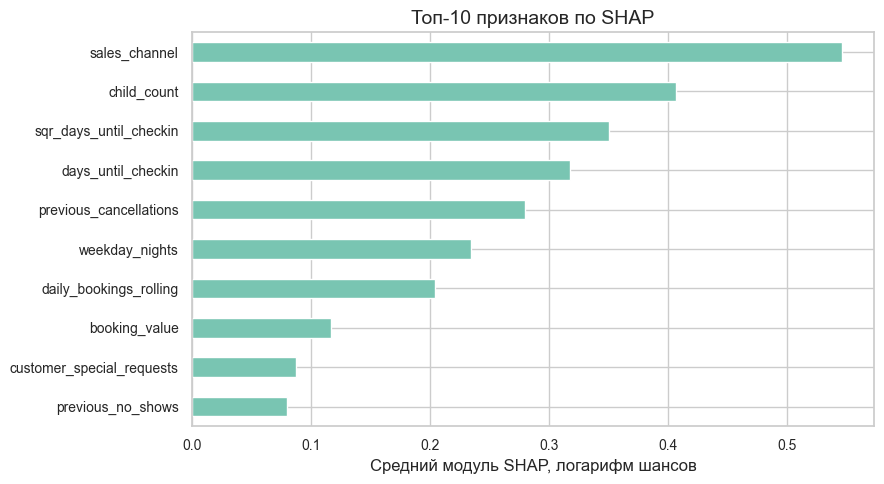

In [72]:
# строим топ-10 признаков по среднему абсолютному shap
shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=X_shap.columns,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))

shap_importance.head(10).sort_values().plot.barh(
    ax=ax, color='#79c5b2'
)

ax.set(
    title='Топ-10 признаков по SHAP',
    xlabel='Средний модуль SHAP, логарифм шансов',
    ylabel='',
)
plt.tight_layout()
plt.show()

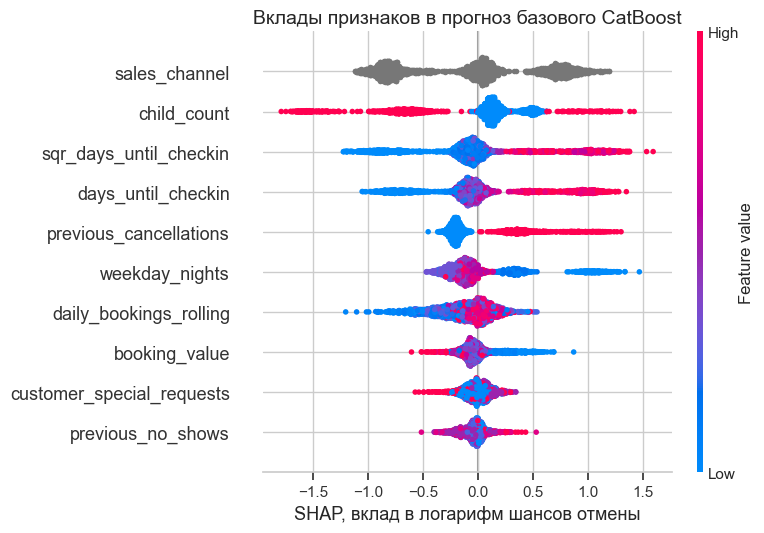

In [73]:
# показываем направление и разброс влияния признаков
shap.summary_plot(
    shap_values,
    X_shap,
    max_display=10,
    plot_type='dot',
    show=False,
)

plt.title('Вклады признаков в прогноз базового CatBoost')
plt.xlabel('SHAP, вклад в логарифм шансов отмены')
plt.tight_layout()
plt.show()

### Выводы по анализу важности признаков (SHAP)

Наибольший вклад в прогноз CatBoost вносит канал продаж (`sales_channel`). Также важны количество детей, срок до заезда, история отмен и количество будних ночей. Большой срок предварительного бронирования и большее число прошлых отмен обычно повышают прогнозируемый риск отмены. Влияние количества детей неоднозначно: высокие значения встречаются как среди положительных, так и среди отрицательных вкладов SHAP.

**Среди созданных признаков:**

- `sqr_days_until_checkin` занял третье место по важности. Большие значения преимущественно повышают прогноз отмены. 
- `daily_bookings_rolling` занял седьмое место. Модель использует информацию об активности канала за предыдущие семь дней, хотя её вклад заметно меньше, чем у ведущих признаков. Однозначного направления влияния на графике нет.
- `value_per_night` не вошёл в топ-10, поэтому его вклад относительно ведущих признаков невелик.

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> 👍</font>

## Выводы по этапу 2

На этапе моделирования данные разделены хронологически на обучающую, калибровочную и тестовую выборки в пропорции 60/20/20. Сравнены DummyClassifier, XGBoost и CatBoost на трёх временных фолдах с размером валидации 2000 наблюдений. Для двух моделей бустинга выполнено по 30 испытаний Optuna с максимизацией Incremental Revenue. Лучший результат показал **CatBoost: средний IR после оптимизации составил 20,44 млн руб. на фолд**.

Выбранная модель обучена на всей тренировочной выборке и откалибрована сигмоидным методом. Калибровка немного ухудшила Brier Score и Log Loss, сохранив ROC-AUC. Согласно ТЗ, дальнейший подбор порога выполнен для откалиброванной модели. Оптимальный порог **0,357957** повысил IR на калибровочной выборке с 61,82 до 67,52 млн руб. за счёт выявления большего числа отмен.

На тестовой выборке получены **ROC-AUC 0,801, Precision 0,552, Recall 0,545 и F1 0,549**. Модель выявила 858 отмен, пропустила 716 и допустила 696 ложных срабатываний. Способность ранжировать бронирования по риску сохранилась, однако качество классификации при фиксированном пороге снизилось относительно калибровочной выборки.

В принятой экономической модели тестовый **Incremental Revenue составил 44,19 млн руб. (+22,84%)**. Экономический эффект положительный, но целевой прирост 50% не достигнут. При интерпретации результата учитываем ограничение данных: отзывы и производные от них признаки исключены из-за утечки при объединении. Это ограничило доступную информацию о клиентах, однако оценить возможный выигрыш от корректного присоединения отзывов по имеющимся данным нельзя.

По SHAP наиболее важен канал продаж; существенный вклад также вносят количество детей, срок до заезда и история отмен. Из созданных признаков `sqr_days_until_checkin` занял третье место, `daily_bookings_rolling` седьмое, а `value_per_night` не вошёл в топ-10. 

Итоговое решение зафиксировано в `final_model`, порог в `final_threshold`.

# Этап 3: расчёт экономической эффективности модели

Оцените, насколько выгодно внедрять выбранную модель в работу отеля. Для этого нужно выяснить, какой экономический эффект даёт модель и укладываются ли ключевые метрики в заданный уровень.

Если расчёты покажут, что какой-либо показатель не достигает необходимого уровня, то это сигнал к доработке модели. Возможно, вам нужно пересмотреть порог классификации, добавить новые признаки, поменять модель, по-другому предобработать исходные данные — экспериментируйте!

- Шаг 1: подготовка данных. Подготовьте данные для расчётов. Данные для показателей до внедрения модели рассчитывайте с использованием тестовых данных `y_test`, данные после внедрения получите с помощью предсказаний модели `y_pred`.

- Шаг 2: расчёт показателей до и после внедрения модели. Вычислите:
  - Долю отмен бронирования до и после внедрения модели;
  - Загрузку отеля до и после внедрения модели;
  - IR.

- Шаг 3: расчёт динамики показателей. Вычислите:
  - Динамику доли отмен бронирования;
  - Динамику загрузки отеля;
  - Относительный IR — на сколько процентов `IR_после` выше, чем `IR_до`.


Ваша модель должна достигнуть следующих результатов:

- Доля отмен после внедрения модели — 10%

- Загрузка отеля не должна уменьшиться больше чем на 8% после внедрения модели.

- Относительный IR должен составить не менее 50%.

Сделайте выводы о том, получилось ли достичь целевых показателей для бизнеса.

<div class="alert alert-info">
<b>Комментарий для ревьюера</b><br><br>

В итоговом решении приоритет отдан корректности оценки и использованию признаков, доступных на момент прогнозирования. При объединении таблиц обнаружена зависимость доступности отзывов от целевого признака, поэтому отзывы и производные от них признаки исключены из моделирования. Это осознанное решение, позволяющее избежать завышения метрик за счёт утечки.

<br><br>

После подбора гиперпараметров, калибровки и выбора порога модель показала на тестовой выборке положительный расчётный экономический эффект: прирост дохода составил 44,19 млн руб. (+22,84%), а доля некомпенсированных отмен - 11,65%. Эти значения отличаются от ориентиров задания: не менее 50% прироста дохода и не более 10% отмен.

<br><br>

В обсуждении проекта представители курса и участники отмечали различия в подходах к использованию таблицы отзывов: эталонное решение включает текстовые признаки, тогда как часть ревьюеров рекомендует исключать их. Поэтому прошу уточнить применимость целевых ориентиров к варианту решения, построенному только на данных бронирований. Влияние корректно связанных исторических отзывов на качество модели по имеющимся данным оценить нельзя.

<br><br>

Выбранный порог сохранён по результатам калибровочной выборки; тестовая выборка использована для итоговой оценки. Полученные результаты представлены для фактически использованного состава признаков и принятого экономического сценария.
</div>

<font color='blue'><b>Комментарий ревьюера : </b></font> ❌\
<font color='blue'> Написал выше.</font> 

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Пока не меняю.</font>

## 13. Оценка экономической эффективности

Расчёты выполняются для фиксированного набора исходных бронирований. Повторная продажа заменяет исходное бронирование и не увеличивает общее число наблюдений.

В принятом сценарии:
- TN: исходное бронирование реализовано;
- TP: отмена выявлена, освободившийся номер повторно продан;
- FN: отмена пропущена и не компенсирована повторной продажей;
- FP: исходное бронирование потеряно из-за ошибочного предупреждения; соответствующие потери учитываются отдельно.

Показатель после применения модели рассчитывается как **доля некомпенсированных отмен исходного портфеля: FN / N**. Для TP предполагается успешная повторная продажа. Целевой уровень 10% в расчётах сопоставляется именно с этой величиной.

Доля реализованных бронирований составляет `(TN + TP) / N`, доля потерь из-за ложных предупреждений составляет `FP / N`. Вместе с долей некомпенсированных отмен эти категории образуют 100% исходного портфеля.

### 13.1. Оценка экономической эффективности

Рассчитаем показатели на тестовой выборке до и после применения итоговой модели.

Для сценария после внедрения принимаем следующие допущения:
- выявленные отмены (TP) позволяют повторно продать бронирование;
- ложные срабатывания (FP) приводят к потере исходного бронирования;
- пропущенные отмены (FN) остаются нереализованными;
- правильно определённые бронирования без отмены (TN) сохраняются.

Долю некомпенсированных отмен исходного портфеля рассчитываем как FN от общего количества тестовых бронирований. Загрузку оцениваем условно как долю реализованных бронирований: до применения модели (TN + FP) / N, после (TN + TP) / N. 

Снижение загрузки на 8% трактуем как относительное изменение, отдельно показываем изменение в процентных пунктах.

In [74]:
# динамика здесь равна (после - до) / до; отрицательное значение означает снижение
# используем тестовые прогнозы, полученные с итоговым порогом
y_pred = test_predict

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

n_bookings = len(y_test)

# рассчитываем показатели до применения модели
cancel_before = y_test.mean()
occupancy_before = (tn + fp) / n_bookings
revenue_before = (tn + fp) * 64500 - (tp + fn) * 64500

# рассчитываем показатели после применения модели по принятому сценарию

# рассчитываем долю исходных отмен, не компенсированных повторной продажей
cancel_after = fn / n_bookings
occupancy_after = tn / n_bookings  # исправил

revenue_after = tp * 45000 + tn * 64500 - fp * 7000 - fn * 64500

# рассчитываем абсолютный и относительный прирост дохода
ir = revenue_after - revenue_before
relative_ir = ir / revenue_before * 100 if revenue_before != 0 else np.nan

# рассчитываем динамику доли отмен и условной загрузки
cancel_change_pp = (cancel_after - cancel_before) * 100
cancel_change_pct = (
    (cancel_after / cancel_before - 1) * 100
    if cancel_before != 0 else np.nan
)

occupancy_change_pp = (occupancy_after - occupancy_before) * 100
occupancy_change_pct = (
    (occupancy_after / occupancy_before - 1) * 100
    if occupancy_before != 0 else np.nan
)

<span style="color: blue; font-weight: bold">Комментарий ревьюера : </span>  ❌\
<font color='red'>
`occupancy_after = (tn + tp) / n_bookings`. Но в контексте данной брони при tp заселения не происходит, поскольку модель отменяет бронь. Нужно считать только реально занятые номера (TN), когда номер свободен и может быть снова забронирован — это не заселённый номер.
</font>

<font color='blue'><b>Комментарий Студента : </b></font> \
<font color='purple'> Исправлено.</font>

In [75]:
# сравниваем показатели до и после применения модели
business_results = pd.DataFrame({
    'До применения': [
        cancel_before * 100,
        occupancy_before * 100,
        revenue_before,
    ],
    'После применения': [
        cancel_after * 100,
        occupancy_after * 100,
        revenue_after,
    ],
    'Изменение': [
        cancel_change_pp,
        occupancy_change_pp,
        ir,
    ],
    'Единица изменения': ['п.п.', 'п.п.', 'руб.'],
    'Относительное изменение, %': [
        cancel_change_pct,
        occupancy_change_pct,
        relative_ir,
    ],
}, index=[
    'Доля некомпенсированных отмен, %',
    'Условная загрузка, %',
    'Доход по экономической модели, руб.',
])

display(business_results.round(2))
print(f'Incremental Revenue: {ir:,.2f} руб.')
print(f'Относительный Incremental Revenue: {relative_ir:.2f}%')

,До применения,После применения,Изменение,Единица изменения,"Относительное изменение, %"
"Доля некомпенсированных отмен, %",25.590,13.170,-12.420,п.п.,-48.540
"Условная загрузка, %",74.410,65.160,-9.250,п.п.,-12.430
"Доход по экономической модели, руб.",185824500.000,227049000.000,41224500.000,руб.,22.180


Incremental Revenue: 41,224,500.00 руб.
Относительный Incremental Revenue: 22.18%


### 13.2. Проверка целевых показателей

Проверим выполнение трёх условий: доля некомпенсированных отмен исходного портфеля не выше 10%, относительное снижение условной загрузки не более 8%, относительный Incremental Revenue не ниже 50%.

Результаты относятся к принятому сценарию действий и повторной продажи бронирований. Они не являются измеренным эффектом реального внедрения.

In [76]:
# проверяем выполнение бизнес-требований
business_targets = pd.DataFrame({
    'Требование': [
        'Не более 10%',
        'Не ниже −8%',
        'Не менее 50%',
    ],
    'Фактическое значение, %': [
        cancel_after * 100,
        occupancy_change_pct,
        relative_ir,
    ],
    'Выполнено': [
        cancel_after <= 0.10,
        occupancy_change_pct >= -8,
        relative_ir >= 50,
    ],
}, index=[
    'Доля некомпенсированных отмен после применения',
    'Относительное изменение условной загрузки',
    'Относительный Incremental Revenue',
])

business_targets['Выполнено'] = business_targets['Выполнено'].map({
    True: 'Да',
    False: 'Нет',
})
# уточняем название расчётного показателя
business_targets = business_targets.rename(index={
    'Относительное изменение условной загрузки':
    'Изменение доли сохранённых исходных броней (прокси)'
})

business_targets.loc[
    'Изменение доли сохранённых исходных броней (прокси)', 'Выполнено'
] = (
    'Да, для условного показателя'
    if occupancy_change_pct >= -8
    else 'Нет, для условного показателя'
)

# отдельно показываем проверку фактической загрузки номеров
business_targets.loc['Фактическая загрузка номерного фонда'] = [
    'Не ниже −8%',
    np.nan,
    'Не проверено: нужны данные о занятых и доступных номеро-ночах'
]
display(business_targets.round(2))

,Требование,"Фактическое значение, %",Выполнено
Доля некомпенсированных отмен после применения,Не более 10%,13.170,Нет
Изменение доли сохранённых исходных броней (прокси),Не ниже −8%,-12.430,"Нет, для условного показателя"
Относительный Incremental Revenue,Не менее 50%,22.180,Нет
Фактическая загрузка номерного фонда,Не ниже −8%,NaN,Не проверено: нужны данные о занятых и доступных номеро-ночах


## Выводы по этапу 3: расчёт экономической эффективности

На тестовой выборке при пороге **0,357957** доля некомпенсированных отмен исходного портфеля снизилась с **25,61% до 11,65%**, или на **13,96 п.п.** Относительное снижение составило **54,51%**. Остаток составил 716 пропущенных отмен из 6 147 бронирований. Целевой уровень 10% превышен на **1,65 п.п.**

Условная доля реализованных бронирований выросла с **74,39% до 77,03%**, или на **3,54%** относительно исходного уровня. Для этого показателя ограничение на снижение не более 8% выполнено. Фактическая загрузка номерного фонда не рассчитана: в исходных таблицах нет данных о доступных номерах и их занятости за сопоставимые периоды.

Расчётный доход увеличился со **193,44 до 237,62 млн руб.** Incremental Revenue составил **44,19 млн руб., или 22,84%**. Экономический эффект положительный, но ниже целевого прироста 50%.

Два числовых ориентира, по некомпенсированным отменам и IR, не достигнуты. Ограничение по загрузке соблюдается только для условного показателя. Результаты относятся к принятому сценарию повторной продажи; фактический эффект за шесть месяцев и ориентир загрузки 80% требуют наблюдения после внедрения.

# Этап 4: выводы по проекту

Выводы должны состоять из двух логически связанных разделов:

- «Проделанная работа» — описание этапов и решений;

- «Бизнес‑выводы» — интерпретация результатов и рекомендации.

В каждом разделе опишите результаты без избыточной детализации, с опорой на факты и цифры.

## Выводы о проделанной работе

В этом разделе опишите основные этапы проделанной работы по построению модели. Опишите, как проходили следующие шаги:
- Подготовка данных;
- Моделирование;
- Оценка метрик;
- Анализа важности факторов.

## 14. Проделанная работа

Данные о бронированиях и отзывах загружены из PostgreSQL с помощью SQLAlchemy и `pd.read_sql_query`. Проведён исследовательский анализ обеих таблиц: проверены типы данных, пропуски, дубликаты, аномалии и распределения признаков. В таблице бронирований удалены 4 608 полных дубликатов, исправлено название категории питания; количество взрослых преобразовано по принятой гипотезе ошибки масштаба. После очистки осталось **30 733 бронирования**.

Для объединения таблиц сначала восстановлена связь `booking_id → customer_id`, затем с помощью `merge_asof` с направлением `backward` подобран ближайший предыдущий отзыв того же клиента при строгом условии `review_date < booking_date`. Проверка показала, что восстановленная связь с клиентом доступна только для неотменённых бронирований. Поэтому даже подбор предыдущего отзыва сохранял зависимость доступности информации от целевой переменной. Объединение, обработка и векторизация текстов выполнены, но отзывы и производные от них признаки исключены из моделирования для предотвращения утечки.

Созданы три признака на основе бронирований:

- `sqr_days_until_checkin`: квадрат числа дней до заезда;
- `value_per_night`: стоимость бронирования в расчёте на одну ночь;
- `daily_bookings_rolling`: количество бронирований за предыдущие семь дней по соответствующему каналу продаж.

Подготовка данных объединена в функцию. Категориальные столбцы приведены к типу `category`. После сортировки по дате данные разделены хронологически: **60% для обучения, 20% для калибровки и 20% для тестирования**.

Сравнены DummyClassifier, XGBoost и CatBoost. Для оценки использована временная кросс-валидация с тремя фолдами и валидационной частью по 2 000 наблюдений. Для XGBoost и CatBoost проведена оптимизация через Optuna, по 30 испытаний для каждой модели. Критерием выбора стал средний Incremental Revenue по фолдам.

У обеих моделей подбирались `learning_rate`, `max_depth` и `n_estimators`. Дополнительно у XGBoost оптимизировались `gamma`, `reg_alpha` и `reg_lambda`, у CatBoost параметр `l2_leaf_reg`.

Лучший результат показал **CatBoost со средним IR 20,44 млн руб. на фолд**, у XGBoost показатель составил **19,78 млн руб.** Итоговые параметры CatBoost:

| Параметр | Значение |
|---|---:|
| `learning_rate` | 0.029644108670580135 |
| `depth` (`max_depth`) | 7 |
| `iterations` (`n_estimators`) | 776 |
| `l2_leaf_reg` | 4.085193594396847 |

Выбранная модель обучена на всей тренировочной выборке. На калибровочной выборке выполнена сигмоидная калибровка. Brier Score изменился с 0,158 до 0,159, Log Loss с 0,482 до 0,485, ROC-AUC остался равным 0,799. Для дальнейшего поиска порога использована откалиброванная модель согласно условиям проекта.

Порог **0,357957** выбран по максимальному IR на калибровочной выборке. Его применение вместо стандартного порога 0,5 увеличило расчётный IR с **61,82 до 67,52 млн руб.**

На тестовой выборке модель оценена с зафиксированным порогом:

| Показатель | Калибровочная выборка | Тестовая выборка |
|---|---:|---:|
| ROC-AUC | 0,799 | 0,801 |
| Precision | 0,601 | 0,552 |
| Recall | 0,596 | 0,545 |
| F1 | 0,598 | 0,549 |
| Правильно выявленные отмены, TP | 1 090 | 858 |
| Ложные предупреждения, FP | 725 | 696 |
| Пропущенные отмены, FN | 740 | 716 |
| Правильно определённые бронирования без отмены, TN | 3 591 | 3 877 |
| Incremental Revenue, млн руб. | 67,52 | 44,19 |
| Относительный Incremental Revenue | 42,11% | 22,84% |

Способность модели ранжировать бронирования по риску сохранилась на тестовых данных. При выбранном пороге точность и полнота выявления отмен снизились, при этом расчётный экономический эффект остался положительным.

Для анализа важности выбран **SHAP**, поскольку он позволяет оценить величину и направление вклада признаков в прогноз базового CatBoost. Построены диаграмма десяти наиболее важных признаков и summary plot. Наибольший вклад вносят канал продаж, число детей, срок до заезда и история отмен.

Среди созданных признаков `sqr_days_until_checkin` занял третье место, `daily_bookings_rolling` седьмое. `value_per_night` не вошёл в первую десятку. Подробная интерпретация всех десяти основных признаков приведена в бизнес-выводах.

Итоговая откалиброванная модель зафиксирована в `final_model`, выбранный порог в `final_threshold`.

## Выводы по анализу эффективности модели

В этом разделе ответьте на вопрос: «Что это значит для бизнеса?» Для этого интерпретируйте результаты вашей работы, дайте им экономическую оценку, а заказчику — рекомендации.

Включите следующие пункты:

- Итоговая оценка достижения цели:
  - Вспомните цель проекта и определите, достигнута ли она. Аргументируйте свой ответ.

- Результаты по ключевым метрикам. Для каждого показателя приведите:
  - Значение до внедрения модели.
  - Значение после внедрения.
  - Изменение в процентах с расчётом по формуле.
  
- Сообщите заказчику, достигнуты ли целевые показатели по метрикам.

- Анализ важности признаков:
  - Опишите для заказчиков основные 10 признаков, влияющих на резкие отмены заказов.
  - Кратко объясните, как они влияют на целевую переменную. Пример такого объяснения: «лояльность клиента снижает риск отмены на 15%».

- Рекомендации для бизнеса:
  - Предложите 2–3 конкретных шага по оптимизации работы сети отелей.

## 15. Бизнес-выводы: анализ эффективности модели

Цель проекта состоит в снижении потерь от отмен бронирований при сохранении загрузки отеля и увеличении дохода. Для оценки использована тестовая выборка из **6 147 бронирований**, итоговая откалиброванная модель и заранее выбранный порог **0,357957**.

Расчёты выполнены в рамках принятого экономического сценария, предполагающего повторную продажу правильно выявленных отменённых бронирований и потери при ложных срабатываниях. Полученные значения характеризуют потенциальный эффект применения модели, а не измеренный результат реального внедрения.

| Показатель | До применения | После применения | Абсолютное изменение | Относительное изменение |
|---|---:|---:|---:|---:|
| Доля некомпенсированных отмен | 25,61% | 11,65% | −13,96 п.п. | −54,51% |
| Условная загрузка | 74,39% | 77,03% | +2,64 п.п. | +3,54% |
| Доход по экономической модели | 193,44 млн руб. | 237,62 млн руб. | +44,19 млн руб. | +22,84% |

Относительное изменение рассчитывается по формуле:

\[
\Delta_{\%} =
\frac{\text{Показатель после} - \text{Показатель до}}
{\text{Показатель до}} \times 100\%.
\]

Для дохода:

\[
IR = 237\,622\,500 - 193\,435\,500
= 44\,187\,000\text{ руб.}
\]

\[
IR_{\%} =
\frac{44\,187\,000}{193\,435\,500} \times 100\%
= 22{,}84\%.
\]

Доля некомпенсированных отмен исходного портфеля сократилась с **25,61% до 11,65%**, то есть на **54,51%**. После применения модели в принятом сценарии остаются 716 некомпенсированных отмен из 6 147 бронирований. Условная загрузка увеличилась, поскольку в принятом сценарии число повторно проданных бронирований превысило число потерянных бронирований из-за ложных срабатываний. Этот показатель рассчитан по бронированиям и не является фактической загрузкой номерного фонда по номеро-ночам.

### 15.1. Соответствие целевым показателям

| Требование | Результат | Выполнение |
|---|---:|---|
| Доля некомпенсированных отмен исходного портфеля не более 10% | 11,65% | Нет |
| Относительное снижение загрузки не более 8% | Рост условного показателя на 3,54% | Да для условного показателя; фактическая загрузка не проверена |
| Относительный Incremental Revenue не менее 50% | 22,84% | Нет |

**Расчётный экономический эффект положителен. Цели по отменам и IR не достигнуты; ограничение по загрузке соблюдается только для условной доли реализованных бронирований.** Долю отмен необходимо дополнительно снизить на 1,65 п.п., а относительный прирост дохода ниже целевого на 27,16 п.п.

Отзывы и производные от них признаки исключены из-за зависимости доступности информации от исхода текущей брони. Для оценки пользы исторических отзывов нужна независимая связь клиента со всеми его бронированиями.

### 15.2. Основные признаки, влияющие на прогноз отмены

По результатам SHAP выделены десять наиболее важных признаков. Порядок отражает среднюю величину их вклада в прогноз базового CatBoost до калибровки. Описанные зависимости характеризуют поведение модели, а не причинное влияние на решения гостей.

| Место | Признак | Значение для бизнеса и влияние на прогноз |
|---|---|---|
| 1 | `sales_channel`, канал продаж | Способ оформления бронирования оказался наиболее важным признаком. Разные каналы связаны с различиями в прогнозируемом риске отмены. Однако общий график не позволяет определить, какой именно канал повышает или снижает риск: для этого необходимо сравнить категории отдельно. |
| 2 | `child_count`, число детей | Состав гостей существенно влияет на прогноз. Вклад больших значений встречается как в сторону повышения, так и снижения риска. Поэтому утверждать, что бронирования с детьми всегда отменяются чаще или реже, по этому графику нельзя. |
| 3 | `sqr_days_until_checkin`, квадрат срока до заезда | Созданный признак отражает длительность ожидания между бронированием и заездом. Большие значения преимущественно повышают прогнозируемый риск, маленькие снижают его. Признак содержит ту же исходную информацию, что и срок до заезда, поэтому их важность следует рассматривать совместно. |
| 4 | `previous_cancellations`, предыдущие отмены | Большое число прошлых отмен преимущественно повышает прогнозируемый риск новой отмены. История отмен помогает выделять бронирования, которым стоит уделять дополнительное внимание. |
| 5 | `weekday_nights`, число будних ночей | Малые значения признака у части бронирований заметно повышают прогнозируемый риск. Большие значения чаще дают вклад около нуля или в сторону снижения риска. Зависимость неоднородна и связана с другими характеристиками бронирования. |
| 6 | `days_until_checkin`, срок до заезда | Большой промежуток между оформлением брони и заездом преимущественно повышает прогнозируемый риск отмены, короткий промежуток снижает его. Это позволяет учитывать, насколько заранее гость планирует поездку. |
| 7 | `daily_bookings_rolling`, бронирования за предыдущие семь дней по каналу продаж | Созданный признак характеризует недавнюю активность бронирований в конкретном канале. Он вошёл в десятку важных факторов, но влияет слабее первых шести. На общем графике нет однозначной зависимости «выше активность, выше риск»: вклад встречается в обе стороны. |
| 8 | `previous_no_shows`, показатель предыдущих бронирований клиента | В словаре задания признак описан как число состоявшихся заселений, хотя его название обычно означает незаезды. Поэтому его бизнес-смысл требует уточнения у поставщика данных. На графике большие значения дают вклад в обе стороны, что не позволяет сделать однозначный вывод о направлении зависимости. |
| 9 | `customer_special_requests`, число пожеланий клиента | Признак отражает количество дополнительных запросов при бронировании. Его вклад относительно небольшой; большие значения часто связаны со снижением прогнозируемого риска, но встречаются исключения. Использовать число пожеланий как самостоятельный критерий надёжности бронирования не следует. |
| 10 | `room_type`, категория номера | Категория номера участвует в оценке риска, но её средний вклад существенно ниже, чем у канала продаж. Общий график показывает влияние в обе стороны, однако не позволяет установить направление для каждой категории номера отдельно. |

Из трёх созданных признаков **`sqr_days_until_checkin` занял третье место, а `daily_bookings_rolling` седьмое**. Признак стоимости одной ночи `value_per_night` в первую десятку не вошёл. Таким образом, модель активно использует два созданных признака, однако их самостоятельный вклад в улучшение качества можно установить только сравнением моделей с этими признаками и без них.

Для бизнеса результаты выделяют несколько направлений внимания: канал поступления брони, история отмен, срок до заезда и состав поездки. Эти характеристики целесообразно использовать совместно в модели для определения приоритетов проверки бронирований.

### 15.3. Рекомендации для бизнеса

Модель можно рассматривать как инструмент для пилотной проверки и приоритизации бронирований, требующих внимания сотрудников. Расчётный прирост дохода положителен, однако его реализация зависит от возможности повторной продажи номеров и фактических потерь при ошибочных предупреждениях.

Для дальнейшего развития решения целесообразно:

1. **Дополнить данные для прогнозирования и экономической оценки.** Обеспечить независимую связь бронирований с клиентами, включая отменённые брони, чтобы использовать историю клиента и отзывы, доступные до оформления бронирования. Добавить даты получения итогового статуса, сведения о номерном фонде, занятости и фактических повторных продажах.

2. **Проверить следующий вариант модели на обучающих и калибровочных данных.** Ближайший эксперимент: сравнить текущий CatBoost с вариантом, дополненным взаимодействиями канала продаж со сроком до заезда и историей отмен. Провести сравнение на одинаковых временных фолдах обучающей выборки, затем выбрать порог на калибровочной. Критерий улучшения: рост Incremental Revenue при доле некомпенсированных отмен не выше 10% и относительном снижении условной загрузки не более 8%. После выбора варианта зафиксировать модель и порог, а итоговую независимую проверку провести на новом временном периоде.

3. **Провести пилот с контрольной группой и мониторингом результатов.** Использовать прогноз для приоритетного подтверждения бронирований с высоким риском отмены. Сравнивать с контрольной группой фактические отмены, загрузку, доход и расходы на вмешательство; отдельно учитывать успешность повторной продажи номеров. По результатам пилота оценить достижение бизнес-ориентиров и принять решение о расширении применения модели.

В проекте сохранена оценка без выявленной утечки. Полученный результат отражает возможности модели на доступном наборе признаков и служит основой для пилотной проверки, уточнения данных и согласования реалистичных бизнес-требований.

<font color='blue'><b>Комментарий ревьюера : </b></font> ✔️\
<font color='green'> Очень приятно видеть вывод в конце проекта!\
Приведены ответы на главные вопросы проекта.</font>

In [77]:
print('Все ячейки успешно выполнены!')

Все ячейки успешно выполнены!


<font color='blue'><b>Итоговый комментарий ревьюера</b></font>\
<font color='green'>Андрей, хороший проект получился!
Большое спасибо за проделанную работу. Видно, что приложено много усилий.
Выводы и рассуждения получились содержательными, их было интересно читать.
</font>

<font color='steelblue'>Над проектом ещё стоит поработать - есть рекомендации по дополнению некоторых твоих шагов проекта. Такие рекомендации я отметил жёлтыми комментариями. Будет здорово, если ты учтёшь их - так проект станет структурно и содержательно более совершенным.

Также в работе есть критические замечания. К этим замечаниям я оставил пояснительные комментарии красного цвета, в которых перечислил возможные варианты дальнейших действий. Уверен, ты быстро с этим управишься:)

Если о том, что нужно сделать в рамках комментариев, будут возникать вопросы - оставь их, пожалуйста, в комментариях, и я отвечу на них во время следующего ревью.

Также буду рад ответить на любые твои вопросы по проекту или на какие-либо другие, если они у тебя имеются - оставь их в комментариях, и я постараюсь ответить:)</font>

<font color='blue'><b>Жду твой проект на повторном ревью. До встречи :) </b></font>